# Comprehensive Global Stock Market Research
## Factor-Based Analysis Across 5 Major Markets

**Markets Covered**: China, Europe, Japan, Korea, United States

**Analysis Components**
1. Factor Performance Analysis
2. Sector Analysis
3. Cross-Country Comparison
4. Market Interpretation & Insights

---
## Setup and Data Loading

In [1]:
import configparser

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

from openai import http_client

warnings.filterwarnings('ignore')

# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Color palette for countries
COUNTRY_COLORS = {
    'china': '#E63946',
    'europe': '#457B9D',
    'japan': '#2A9D8F',
    'korea': '#E9C46A',
    'us': '#264653'
}

# Factor colors
FACTOR_COLORS = {
    'BM': '#E63946',
    'HML': '#F4A261',
    'SMB': '#2A9D8F',
    'MOM': '#264653',
    'OP': '#8338EC',
    'INV': '#06D6A0',
    'REV': '#118AB2'
}

# Base path
BASE_PATH = Path('.')
COUNTRIES = ['us', 'europe', 'japan', 'china', 'korea']

print("Setup complete. Loading data...")

Setup complete. Loading data...


In [2]:
# GICS Sector mapping
SECTOR_NAMES = {
    '10': 'Energy',
    '15': 'Materials',
    '20': 'Industrials',
    '25': 'Consumer Disc.',
    '30': 'Consumer Staples',
    '35': 'Health Care',
    '40': 'Financials',
    '45': 'Info Tech',
    '50': 'Comm. Services',
    '55': 'Utilities',
    '60': 'Real Estate'
}

In [3]:
# Data containers
data = {
    'total_ER': {}, # whole univers's equity expected returns
    'beta': {}, # whole universe's equity factor exposure
    'factor_hs': {}, # historical factor returns
    'factor_hs_clipped': {}, # clipped historical factor returns(recent 52 weeks, normalized to 100)
    'factor_ts': {}, # historical factor expected returns
    'factor_ts_clipped': {}, # clipped historical factor expected returns(recent 52 weeks, normalized to 100)
    'index_ts': {}, # historical index expected returns
    'index_ts_clipped': {}, # clipped historical index expected returns(recent 52 weeks, normalized to 100)
    'sector_ts': {}, # historical sector expected returns
    'sector_ts_clipped': {}, # clipped historical sector expected returns(recent 52 weeks, normalized to 100)
    'industry_ts' : {}, # historical industry expected returns
    'industry_ts_clipped': {}, # clipped historical industry expected returns(recent 52 weeks, normalized to 100)
    'factor_ER': {}, # factor expected returns for most recent month
    'index_ER': {}, # index expected returns for most recent month
    'sector_ER': {}, # sector expected returns for most recent month
    'industry_ER': {}, # industry expected returns for most recent month
    'size_ER': {}, # size quintile expected returns for most recent month
    'top_bot': {}, # top and bottom 10 stocks by expected return
}

def clip_ts(df, periods=52):
    """Clip time series to the last 'periods' entries and normalize to 100"""
    clipped = df[-periods:]
    clipped = (clipped / clipped.iloc[0]) * 100
    return clipped

# Load all data
for country in COUNTRIES:
    country_path = BASE_PATH / country

    # Load each file type
    data['total_ER'][country] = pd.read_csv(country_path / 'total_ER.csv', index_col=0, dtype={'sector':str})
    data['beta'][country] = pd.read_csv(country_path / 'beta.csv', index_col=0, dtype={'sector':str, 'industry':str})

    # historical time series of factor index
    data['factor_hs'][country] = pd.read_csv(country_path / 'factor_hs.csv', index_col=0, parse_dates=True)
    data['factor_hs_clipped'][country] = clip_ts(data['factor_hs'][country])
    # time series of factor index's expected return index
    data['factor_ts'][country] = pd.read_csv(country_path / 'factor_ts.csv', index_col=0, parse_dates=True)
    data['factor_ts_clipped'][country] = clip_ts(data['factor_ts'][country])
    # time series of country index's expected return index
    data['index_ts'][country] = pd.read_csv(country_path / 'index_ts.csv', index_col=0, parse_dates=True)
    data['index_ts_clipped'][country] = clip_ts(data['index_ts'][country])
    # time series of sector index's expected return index
    data['sector_ts'][country] = pd.read_csv(country_path / 'sector_ts.csv', index_col=0, parse_dates=True)
    data['sector_ts_clipped'][country] = clip_ts(data['sector_ts'][country])
    # time series of industry index's expected return index
    data['industry_ts'][country] = pd.read_csv(country_path / 'industry_ts.csv', index_col=0, parse_dates=True)
    data['industry_ts_clipped'][country] = clip_ts(data['industry_ts'][country])

    data['factor_ER'][country] = pd.read_csv(country_path / 'factor_ER.csv')
    data['index_ER'][country] = pd.read_csv(country_path / 'index_ER.csv')
    data['sector_ER'][country] = pd.read_csv(country_path / 'sector_ER.csv', dtype={'sector':str})
    data['industry_ER'][country] = pd.read_csv(country_path / 'industry_ER.csv', dtype={'industry':str})

    data['size_ER'][country] = pd.read_csv(country_path / 'size_ER.csv')
    data['top_bot'][country] = pd.read_csv(country_path / 'ERtop+bot10.csv', dtype={'sector':str})

print("Data loaded successfully!")
print(f"\nCountries: {COUNTRIES}")
print(f"\nStock counts by market:")
for country in COUNTRIES:
    print(f"  {country.upper()}: {len(data['total_ER'][country]):,} stocks")

Data loaded successfully!

Countries: ['us', 'europe', 'japan', 'china', 'korea']

Stock counts by market:
  US: 2,938 stocks
  EUROPE: 599 stocks
  JAPAN: 495 stocks
  CHINA: 575 stocks
  KOREA: 295 stocks


In [4]:
# NORMALIZATION FUNCTIONS FOR CROSS-COUNTRY COMPARISON
# Since factor models have different scales across countries, we need to
# normalize values before making cross-country comparisons.

def zscore_normalize(series):
    """Convert to z-scores (mean=0, std=1)"""
    return (series - series.mean()) / series.std()

def normalize(er, ts, er_ind:str, er_col:str, ts_col:str=None):
    """Normalize ER values using z-score based on time series data"""
    er_with_index = er.set_index(er_ind, inplace=False)
    er_val = er_with_index[er_col] / 100
    if ts_col is not None:
        ts_er = ts.filter(like=ts_col, axis=1)
        ts_er.columns = ts_er.columns.str.replace(ts_col, '')
    else:
        ts_er = ts
    ts_mean = ts_er.mean()
    ts_std = ts_er.std()

    data = pd.concat([er_val, ts_mean, ts_std], axis=1)
    data.columns = ['ER', 'Mean', 'Std']
    zscore = (data['ER'] - data['Mean']) / data['Std']
    zscore.name = 'ER_zscore'
    result = pd.concat([er_with_index, zscore], axis=1).dropna()

    return result

# Create normalized versions of key data
print("\n" + "="*70)
print("CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON")
print("="*70)

# Normalize ER data for each country
for country in COUNTRIES:
    # Normalize equity ERs
    total_er = data['total_ER'][country].copy()
    if 'ER' in total_er.columns:
        total_er['ER_zscore'] = zscore_normalize(total_er['ER'])
    data['total_ER'][country] = total_er

    # Normalize index ERs
    er = data['index_ER'][country].copy()
    ts = data['index_ts'][country].copy()

    data['index_ER'][country] = normalize(er, ts, 'index', 'wER', '_ER')

    # Normalize sector ERs
    er = data['sector_ER'][country].copy()
    ts = data['sector_ts'][country].copy()

    data['sector_ER'][country] = normalize(er, ts, 'sector', 'wER', '_ER')

    # Normalize industry ERs
    er = data['industry_ER'][country].copy()
    ts = data['industry_ts'][country].copy()

    data['industry_ER'][country] = normalize(er, ts, 'industry', 'wER', '_ER')

    # Normalize factor returns (relative strength within country)
    er = data['factor_ER'][country].copy()
    ts = data['factor_ts'][country].copy()
    data['factor_ER'][country] = normalize(er, ts, 'factor', 'ER', '_ER')

print("Normalization methods applied:")
print("  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons")
print("  • Note: Use normalized values for cross-country comparisons")


CREATING NORMALIZED DATA FOR CROSS-COUNTRY COMPARISON
Normalization methods applied:
  • Z-Score: Standardized (mean=0, std=1) - good for relative comparisons
  • Note: Use normalized values for cross-country comparisons


In [5]:
# ============================================================
# LLM Commentary Helper  (with persistent conversation memory)
# Requires: pip install openai
# Set environment variable: OPENAI_API_KEY=your-key
# ============================================================
import os
from IPython.display import display, Markdown

OPENAI_MODEL = "gpt-5-mini"  # change to "gpt-4o-mini" for lower cost

# Persistent conversation history — accumulates across all show_explanation() calls
_conversation_history = []

_SYSTEM_MESSAGE = {
    "role": "system",
    "content": (
        "당신은 미국, 유럽, 일본, 중국, 한국을 커버하는 글로벌 멀티팩터 주식 리서치 보고서를 작성하는 "
        "시니어 퀀트 주식 전략가입니다.\n\n"
        "여기서 언급되는 팩터들은 BM(마켓 베타), SML(사이즈-소형주), HML(가치주), MOM(주가모멘텀), OP(퀄리티), INV(보수적 투자)입니다."

        "【서술 구조】\n"
        "각 섹션의 해설은 몇 개의 주제별 단락으로 구성하십시오. "
        "번호 매긴 항목(1., 2., 3. 또는 1.1, 1.2 등)이나 불릿 포인트(•, -, *)로 내용의 가독성을 향상해주세요. "
        "각 단락은 하나의 핵심 주제를 다루며, 도입 문장 → 근거 및 데이터 해석 → "
        "투자 시사점 순으로 자연스럽게 이어지는 완결된 문단으로 작성하십시오. "
        "단락 사이에는 논리적 연결이 있어야 하며, 전체 해설이 하나의 일관된 분석으로 읽혀야 합니다.\n\n"

        "【서술 깊이】\n"
        "수치를 단순 나열하는 대신, 그 수치가 의미하는 바를 충분히 풀어 설명하십시오. "
        "예를 들어 '모멘텀 팩터의 4주 수익률이 +2.3%로 가속되었다'에서 그치지 말고, "
        "이 가속이 어떤 시장 환경을 반영하는지, 장기 패턴과 어떻게 다른지, "
        "투자자 입장에서 어떤 행동을 시사하는지까지 서술하십시오. "
        "전문 용어(Z-스코어, 최대 낙폭, 팩터 프리미엄, 기대수익률 등)는 "
        "독자가 문맥 안에서 자연스럽게 이해할 수 있도록 설명을 내포하여 사용하십시오.\n\n"

        "【분석 우선순위】\n"
        "분석 기간은 52주이나, 최근 4~8주간의 변화에 서술의 무게중심을 두십시오. "
        "52주 전체 맥락은 현재 상황을 이해하기 위한 배경으로만 간략히 언급하고, "
        "최근 추세의 방향·크기·가속 여부, 그리고 그것이 장기 패턴을 확인하는지 "
        "반박하는지를 중심으로 서술하십시오.\n\n"

        "【보고서 연속성】\n"
        "각각의 섹션들이 분석되는 순서는 매우 중요한 의미를 지닙니다. "
        "이전 섹션에서 도출된 인사이트를 이후 섹션에서 자연스럽게 참조하여 "
        "보고서 전체에 걸쳐 일관된 분석 서사를 유지하십시오.\n\n"

        "문체는 투자위원회 보고서에 적합한 격식체(명사형 문장)를 유지하십시오. "
        "모든 응답은 반드시 한국어로 작성하십시오."
    )
}

def reset_conversation():
    """Clear conversation history to start a fresh report."""
    global _conversation_history
    _conversation_history = []
    print("대화 기록이 초기화되었습니다.")

def llm_explain(data_str: str, prompt: str) -> str:
    """Generate narrative explanation, maintaining full conversation context."""
    global _conversation_history
    try:
        from openai import OpenAI
        import httpx
        key = os.getenv('OPENAI_API_KEY', '')
        if not key:
            return "_LLM 해설을 사용할 수 없습니다 — `OPENAI_API_KEY` 환경 변수를 설정하세요._"

        client = OpenAI(api_key=key, http_client=httpx.Client(verify=False))

        user_message = {"role": "user", "content": f"{prompt}\n\nData:\n{data_str}"}
        messages = [_SYSTEM_MESSAGE] + _conversation_history + [user_message]

        response = client.responses.create(
            model=OPENAI_MODEL,
            #max_output_tokens=1500,
            input=messages
        )
        #reply = response.choices[0].message.content
        reply = response.output_text

        _conversation_history.append(user_message)
        _conversation_history.append({"role": "assistant", "content": reply})

        return reply
    except ImportError:
        return "_`openai` 패키지가 설치되지 않았습니다 — `pip install openai`를 실행하세요._"
    except Exception as e:
        return f"_LLM 오류: {e}_"

def show_explanation(data_str: str, prompt: str, title: str = "분석 해설"):
    """Generate and display LLM commentary as Markdown."""
    text = llm_explain(data_str, prompt)
    display(Markdown(f"---\n### 💬 {title}\n\n{text}\n\n---"))

reset_conversation()
print(f"LLM 헬퍼 로드 완료. 모델: {OPENAI_MODEL}")
print("대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)")
print("API 키:", "✓ 설정됨" if os.getenv('OPENAI_API_KEY') else "✗ 미설정 (OPENAI_API_KEY 환경 변수를 설정하세요)")

대화 기록이 초기화되었습니다.
LLM 헬퍼 로드 완료. 모델: gpt-5-mini
대화 메모리: 활성화 (초기화하려면 reset_conversation() 호출)
API 키: ✓ 설정됨


---
## Historical Analysis

### Factor Time Series Performance

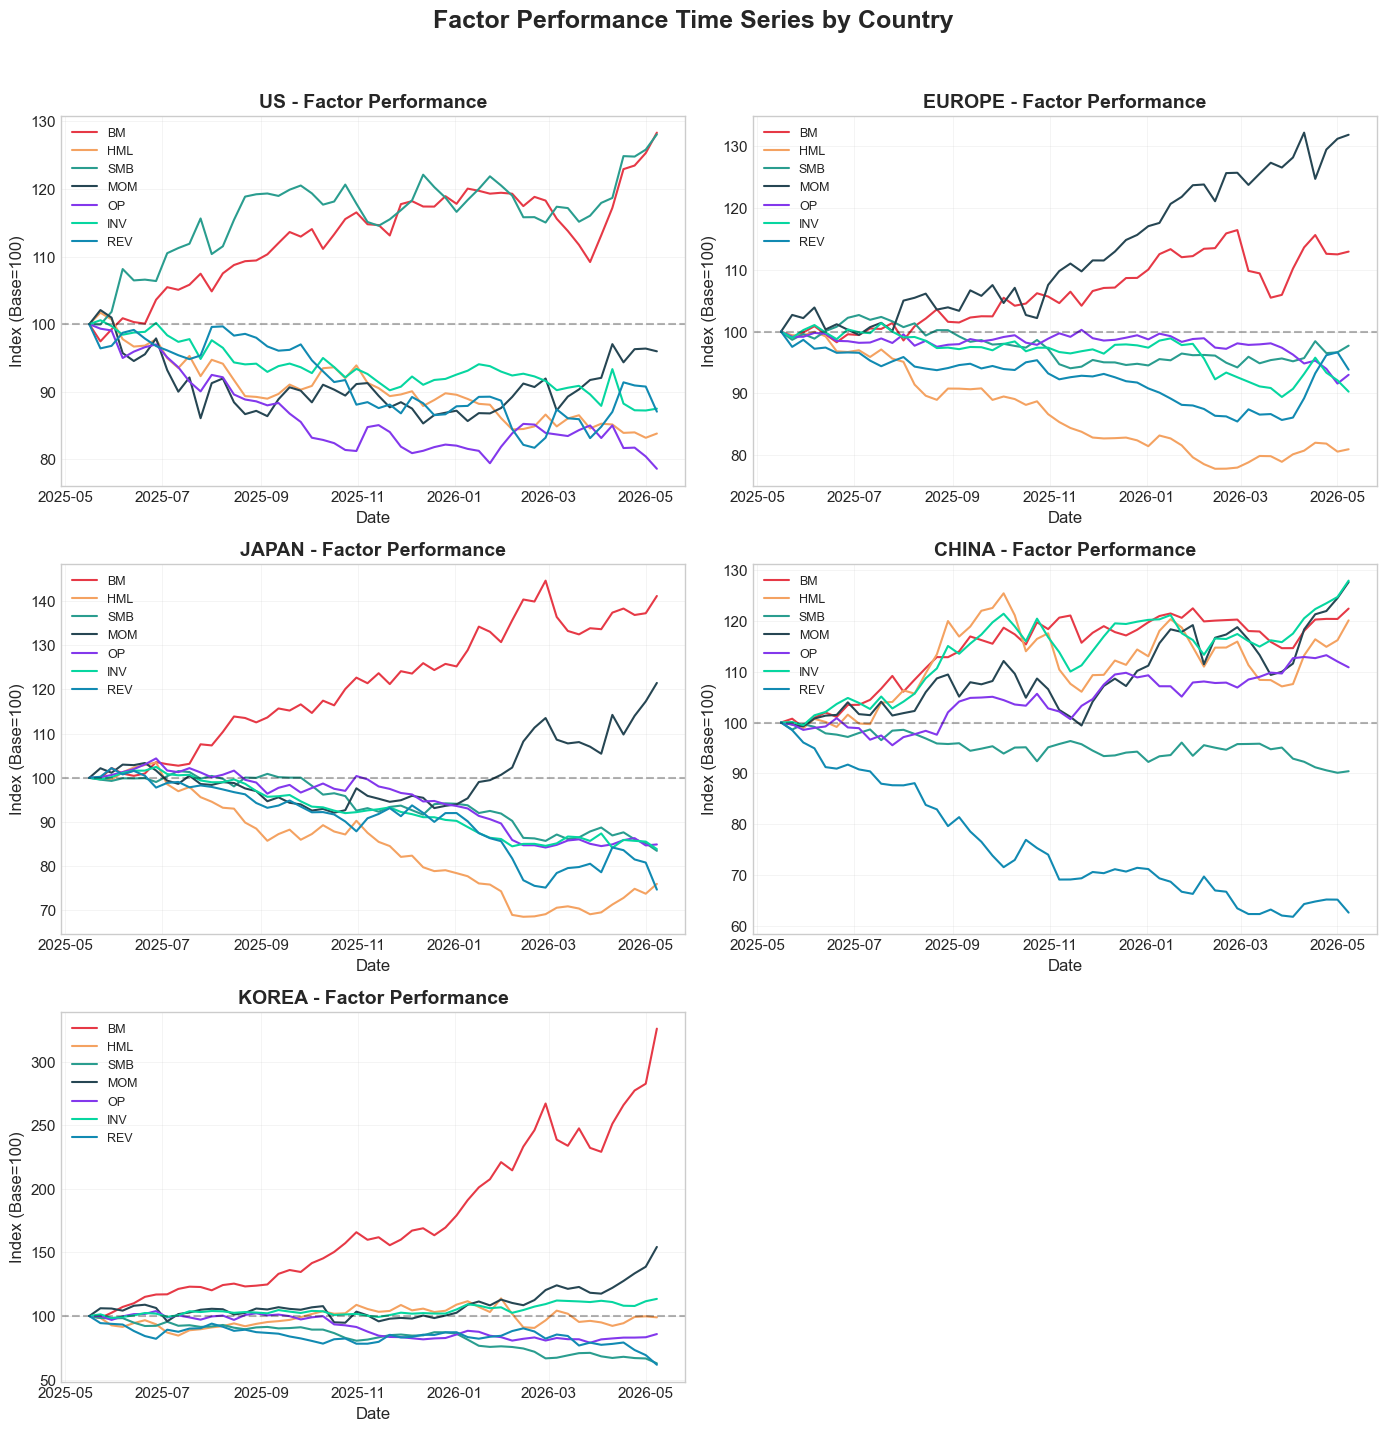

In [6]:
# Plot factor time series for each country
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_ts = data['factor_hs_clipped'][country]

    for col in factor_ts.columns:
        if col in FACTOR_COLORS:
            ax.plot(factor_ts.index, factor_ts[col], label=col,
                   color=FACTOR_COLORS.get(col, 'gray'), linewidth=1.5)

    ax.axhline(y=100, color='black', linestyle='--', alpha=0.3)
    ax.set_title(f'{country.upper()} - Factor Performance', fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Index (Base=100)')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)

# Hide the 6th subplot
axes[5].axis('off')

plt.suptitle('Factor Performance Time Series by Country', fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
# Calculate factor statistics
def calculate_factor_stats(factor_ts):
    """Calculate comprehensive factor statistics"""
    returns = factor_ts.pct_change().dropna()

    stats = pd.DataFrame({
        'Total Return (%)': ((factor_ts.iloc[-1] / factor_ts.iloc[0]) - 1) * 100,
        'Ann. Return (%)': returns.mean() * 52 * 100,
        'Ann. Vol (%)': returns.std() * np.sqrt(52) * 100,
        'Sharpe Ratio': (returns.mean() * 52) / (returns.std() * np.sqrt(52)),
        'Max Drawdown (%)': ((factor_ts / factor_ts.cummax()) - 1).min() * 100,
        'Skewness': returns.skew(),
        'Kurtosis': returns.kurtosis()
    })
    return stats.round(3)

# Display factor stats for each country
for country in COUNTRIES:
    print(f"\n{'='*70}")
    print(f"{country.upper()} - FACTOR STATISTICS")
    print("="*70)
    stats = calculate_factor_stats(data['factor_hs_clipped'][country])
    display(stats.style.format('{:.3f}').background_gradient(cmap='RdYlGn', subset=['Sharpe Ratio'], axis=0))


US - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,28.323,26.297,12.891,2.040,-9.042,0.263,-0.255
HML,-16.162,-17.321,11.244,-1.540,-18.182,0.002,-0.788
SMB,28.069,26.299,14.447,1.820,-5.789,0.398,0.946
MOM,-4.007,-2.512,18.317,-0.137,-16.417,-0.330,0.484
OP,-21.372,-23.728,12.204,-1.944,-21.372,0.405,0.665
INV,-12.483,-12.883,11.928,-1.080,-13.270,0.664,5.036
REV,-12.926,-12.991,15.017,-0.865,-18.268,0.419,0.854



EUROPE - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,12.963,13.229,12.614,1.049,-9.405,-0.833,1.871
HML,-19.067,-21.143,8.808,-2.400,-22.232,-0.182,0.358
SMB,-2.279,-2.079,7.438,-0.280,-8.403,0.115,0.454
MOM,31.899,29.464,15.360,1.918,-5.667,-0.433,0.949
OP,-7.006,-7.199,6.391,-1.126,-8.686,-0.402,-0.121
INV,-9.736,-10.030,9.061,-1.107,-11.806,0.036,0.510
REV,-6.172,-6.015,9.909,-0.607,-14.570,1.192,2.838



JAPAN - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,41.124,36.271,14.513,2.499,-8.406,-0.332,0.450
HML,-23.982,-26.740,15.169,-1.763,-33.733,-0.478,0.830
SMB,-16.510,-17.910,9.608,-1.864,-17.766,-0.413,0.689
MOM,21.464,21.266,17.064,1.246,-10.867,0.966,1.823
OP,-15.064,-16.187,9.383,-1.725,-19.300,-0.172,1.172
INV,-16.117,-17.599,7.667,-2.295,-18.140,-0.242,1.374
REV,-25.283,-28.188,17.130,-1.646,-26.886,0.150,2.695



CHINA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,22.386,21.331,11.886,1.795,-6.393,-0.440,0.222
HML,20.069,20.549,19.502,1.054,-15.425,-0.277,-0.250
SMB,-9.573,-9.840,9.146,-1.076,-9.880,0.195,0.209
MOM,27.602,26.653,18.828,1.416,-11.313,-0.363,-0.052
OP,10.846,11.063,10.659,1.038,-5.284,0.464,0.378
INV,27.878,26.009,13.367,1.946,-9.355,-0.385,-0.635
REV,-37.361,-45.968,17.505,-2.626,-38.177,0.295,0.626



KOREA - FACTOR STATISTICS


,Total Return (%),Ann. Return (%),Ann. Vol (%),Sharpe Ratio,Max Drawdown (%),Skewness,Kurtosis
BM,226.032,126.687,31.478,4.025,-14.221,-0.169,1.544
HML,-1.032,3.434,30.140,0.114,-20.408,-0.253,0.735
SMB,-37.192,-45.711,17.296,-2.643,-37.192,-0.595,0.114
MOM,54.348,48.730,29.486,1.653,-13.005,-0.449,1.884
OP,-14.173,-14.102,17.173,-0.821,-23.971,-0.319,-0.375
INV,13.498,13.705,12.619,1.086,-6.165,-0.089,-0.193
REV,-38.335,-45.280,27.572,-1.642,-38.335,-0.133,0.511


### Factor Correlation Analysis

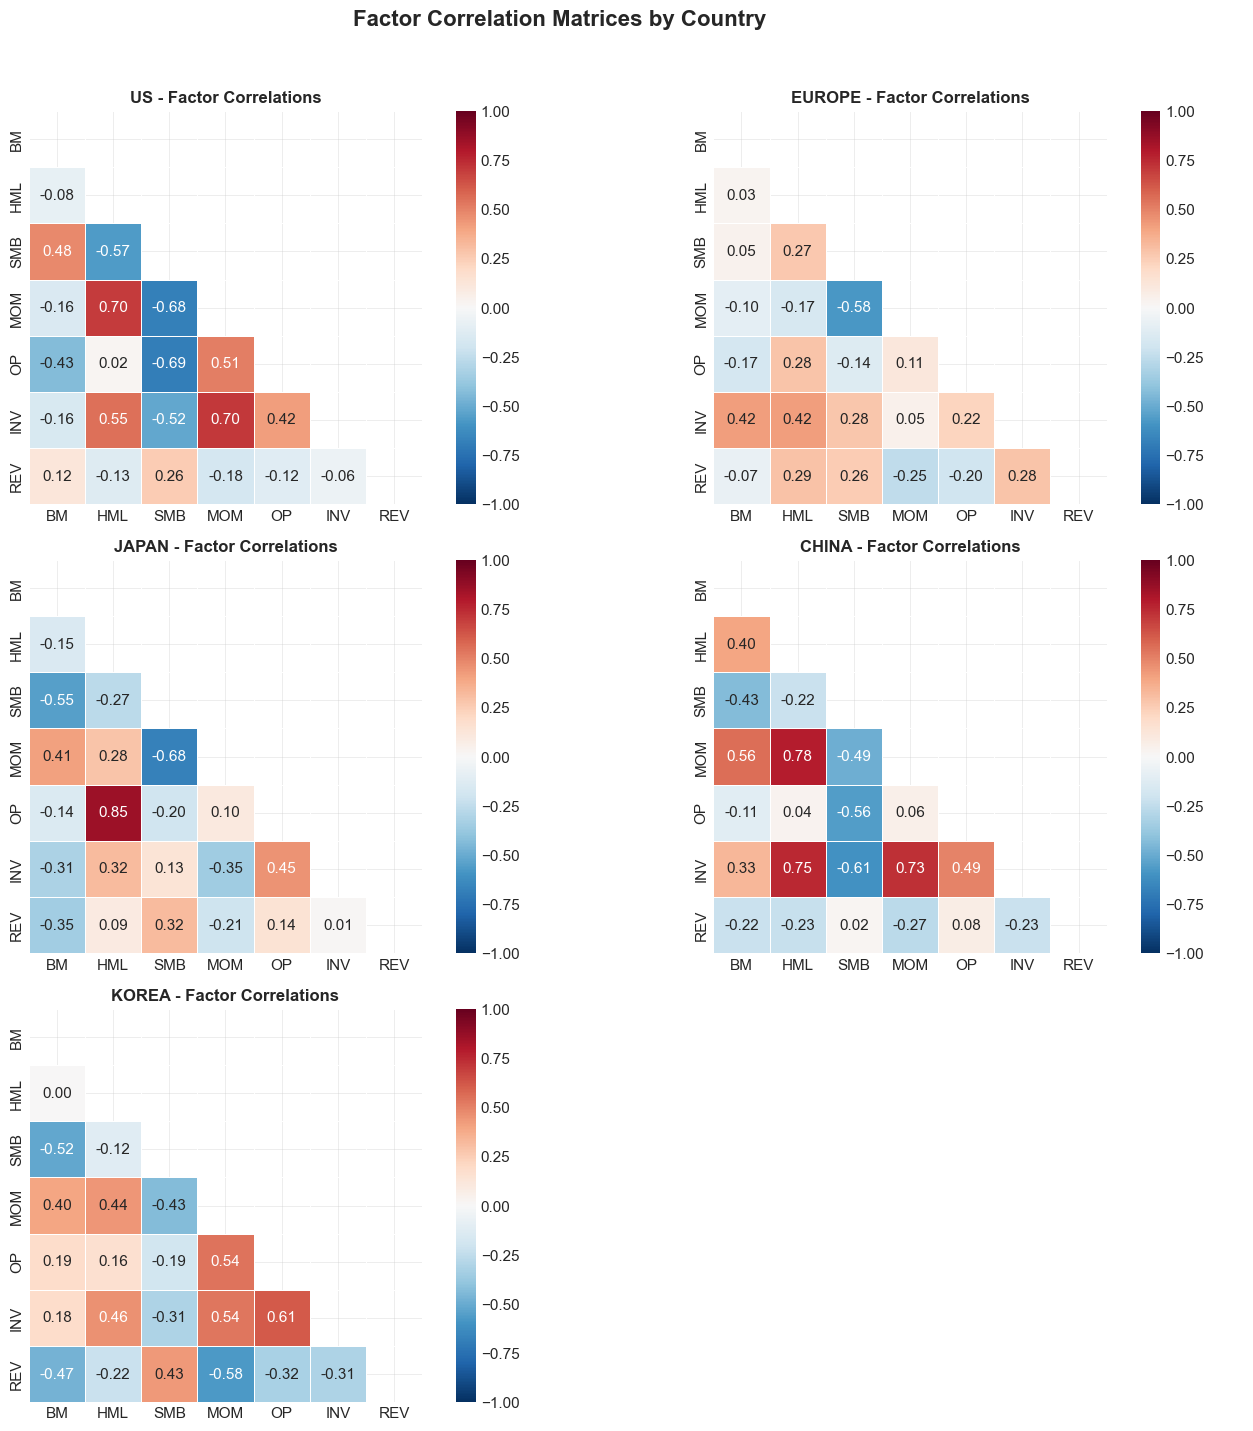

In [8]:
# Factor correlation matrices
fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    factor_returns = data['factor_hs_clipped'][country].pct_change().dropna()
    corr = factor_returns.corr()

    mask = np.triu(np.ones_like(corr, dtype=bool))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
                center=0, ax=ax, vmin=-1, vmax=1,
                square=True, linewidths=0.5)
    ax.set_title(f'{country.upper()} - Factor Correlations', fontsize=12, fontweight='bold')

axes[5].axis('off')
plt.suptitle('Factor Correlation Matrices by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [9]:
# === LLM Commentary: Historical Analysis ===
_hist_txt = "HISTORICAL ANALYSIS - Factor Performance & Correlations\n\n"

# Part A: Factor Statistics (52w + recent 4/8w)
_hist_txt += "=== PART A: FACTOR PERFORMANCE STATISTICS ===\n\n"
for _c in COUNTRIES:
    _hs = data['factor_hs_clipped'][_c]
    _full = calculate_factor_stats(_hs)
    _ret4  = (_hs.iloc[-1] / _hs.iloc[-5]  - 1) * 100 if len(_hs) >= 5  else pd.Series(dtype=float)
    _ret8  = (_hs.iloc[-1] / _hs.iloc[-9]  - 1) * 100 if len(_hs) >= 9  else pd.Series(dtype=float)
    _prior4 = (_hs.iloc[-5] / _hs.iloc[-9] - 1) * 100 if len(_hs) >= 9  else pd.Series(dtype=float)
    _accel  = _ret4 - _prior4
    _hist_txt += f"{'='*38}\n{_c.upper()}\n{'='*38}\n"
    _hist_txt += "Factor | Sharpe | MaxDD(%) | 4w Ret(%) | 8w Ret(%) | Accel\n"
    for _f in _full.index:
        _sh  = _full.loc[_f, 'Sharpe Ratio']
        _dd  = _full.loc[_f, 'Max Drawdown (%)']
        _r4  = _ret4.get(_f,   float('nan'))
        _r8  = _ret8.get(_f,   float('nan'))
        _acc = _accel.get(_f,  float('nan'))
        _dir = "ACCEL↑" if _acc > 0 else "DECEL↓"
        _hist_txt += (
            f"  {_f:5}: Sharpe={_sh:+.2f} | MaxDD={_dd:.1f}% "
            f"| 4w={_r4:+.2f}% | 8w={_r8:+.2f}% | {_dir}({_acc:+.2f}%)\n"
        )
    _hist_txt += "\n"

# Part B: Factor Correlations (full 52w + recent 8w change)
_hist_txt += "=== PART B: FACTOR CORRELATIONS ===\n\n"
for _c in COUNTRIES:
    _ret_full   = data['factor_hs_clipped'][_c].pct_change().dropna()
    _ret_recent = data['factor_hs_clipped'][_c].iloc[-8:].pct_change().dropna()
    _corr_full   = _ret_full.corr().round(2)
    _corr_recent = _ret_recent.corr().round(2) if len(_ret_recent) >= 3 else _corr_full
    _corr_diff   = (_corr_recent - _corr_full).round(2)
    _hist_txt += f"{'='*32}\n{_c.upper()}\n{'='*32}\n"
    _hist_txt += "Full-Period Correlation:\n" + _corr_full.to_string() + "\n"
    _hist_txt += "Recent 8-Week Correlation:\n" + _corr_recent.to_string() + "\n"
    _hist_txt += "Change (Recent - Full):\n" + _corr_diff.to_string() + "\n\n"

_hist_prompt = (
"당신은 지금 1.3 Historical Analysis 섹션 종합 해설을 작성합니다.\n\n"
"제공된 데이터는 두 파트로 구성됩니다: "
"Part A — 5개 시장별 7개 팩터의 52주 통계(Sharpe, MaxDD) + 최근 4주/8주 수익률 및 변화(Change) "
"Part B — 전체 기간 vs 최근 8주 팩터 상관관계 행렬, 그리고 그 변화(Change)\n"
"다음 흐름으로 서술하십시오: "
"1.최근 4~8주 기준으로 가속 중인 팩터와 감속 중인 팩터를 구분하여 가장 중요한 변화부터 서술하십시오. "
"2.52주 Sharpe와 최근 추세가 상충하는 팩터(예: 장기 강세이나 최근 감속)를 지적하고, 이것이 의미하는 국면 전환 신호인지 논의하십시오. "
"3.**상관관계 변화 행렬(Change)**에서 가장 큰 움직임을 포착하여, 어떤 팩터가 서로 동행하는지, 혹은 반대되는지 서술하십시오. "
"4.Part A와 Part B를 통합하여 현재 팩터 환경의 구조적 특성과 투자 시사점을 도출하십시오.\n"
"최근 4~8주 변화에 서술의 무게를 두고, 52주 맥락은 배경으로만 간략히 언급하십시오. "
)

show_explanation(_hist_txt, _hist_prompt, title="1.3 Historical Analysis 종합 해설의 실무적 구성")


---
### 💬 1.3 Historical Analysis 종합 해설의 실무적 구성

1. 최근 4–8주 기준 가속·감속 요약 및 우선순위 서술.  
   - 가장 두드러진 가속 현상으로서 한국의 BM(시장베타)·MOM(모멘텀) 팩터의 급격한 가속 확인. 한국 BM의 4주 수익률 +29.79%, 8주 +39.38% 및 가속치 +22.40%는 지역 단기 랠리의 핵심 신호로 해석됨. 동일하게 한국 MOM의 4주 +26.33%·8주 +27.15% 및 가속 +25.69%는 베타 주도 장세와 모멘텀 동조가 동시에 발생하고 있음을 시사함. 투자 시사점으로서 단기적 초과수익 실현·포지션 축소를 고려하되, 과도한 포지션 집중(베타·모멘텀 중복)에 대한 방어적 헤지 필요.  
   - 다음 우선 순위로 미국의 BM·SMB(소형주) 가속과 중국의 MOM·HML(가치)·INV(보수적투자) 가속 관찰. 미국 BM/SMB는 각각 가속 +6.49%/+6.64%와 4주 수익률 각각 +9.49%·+7.92%로 경기순환·리스크온 성격의 소형·시장 베타 선호 전개를 시사. 중국은 MOM(+3.46), HML(+1.65), INV(+1.32) 가속으로 베타·가치·수익성 지표가 동시 상승하는 광범위한 리레이팅 국면을 나타냄. 투자 시사점으로서 각 지역의 펀더멘털·정책 모멘텀(예: 중국의 경기부양 기대)을 확인하여 지역별 차별적 노출 권장.  
   - 뚜렷한 감속·취약 신호로서는 한국·일본·미국에서의 일부 팩터 급락 확인. 특히 한국 REV(리버전) 4주 -21.04%, 8주 -26.85% 및 가속 -13.67%는 특정 군집(예: 가치 회귀 전략)의 급락을 의미하며, 미국에서는 MOM·OP·INV가 최근 4주에 급격히 후퇴(가속치 각각 -9.78, -9.41, -9.30)하여 장기적 약세 팩터들의 단기 붕괴 신호로 해석됨. 투자 시사점으로서 해당 팩터 롱 익스포저 축소 및 대체 헷지(시장중립 포지션 또는 변동성 대응) 권장.

2. 52주 Sharpe와 최근 추세 간 상충 사례 및 국면 전환 논의.  
   - 장기 Sharpe 대비 최근 약화가 의미 있는 사례로서 유럽 MOM을 지목. 유럽 MOM의 52주 Sharpe +1.92로 장기 우수 성과를 보이나 최근 8주 +5.02에서 4주 -0.26로 가속 -5.56을 기록하여 모멘텀 팩터의 단기 소강 국면 가능성을 시사함. 이는 장기 강세 팩터의 단기 조정으로 해석되며, 단순한 조정인지 구조적 전환인지는 향후 변동성·거시 이벤트 확인 필요. 투자 시사점으로서 모멘텀 포지션의 부분 이익실현과 재평가 기준(예: 모멘텀 지속성 지표, 거래량)을 설정한 리밸런싱 권장.  
   - 장기 Sharpe가 부정적이나 최근 강세로 전환된 사례로 일본 HML과 일부 중국 팩터 관찰. 일본 HML의 52주 Sharpe -1.76이었으나 최근 4주 +6.55·8주 +7.15 및 가속 +5.99를 기록, 장기 약세에서 단기 반등으로 전환됨. 해당 패턴은 가치의 재발견 또는 사이클성 업종의 계절적 회복 가능성을 반영하나, 장기 이력상 누적 손실(낙폭)이 큰 점을 고려할 때 신중한 진입(부분적 시드 투자·퀄리티 필터 적용) 권고.  
   - 미국 MOM의 경우 52주 Sharpe는 약화(-0.14)이나 8주 +7.49 이후 4주 -1.09로 급락, 이는 모멘텀의 불안정한 전개로서 조기 반전 신호일 가능성 존재. 투자 시사점으로서 모멘텀 기반 레버리지·집중 포지션에 대한 리스크 컨트롤 강화 권고.

3. 상관관계 변화 행렬(Change)에서 포착되는 가장 큰 움직임과 의미 해석.  
   - 미국의 팩터 클러스터링 가속. 최근 US에서 MOM-OP 상관 변화 +0.44(최근 0.95) 및 MOM-INV +0.18(최근 0.88), OP-INV +0.35(최근 0.77) 등 모멘텀·퀄리티·보수적투자 팩터 간 상관이 대폭 상승하여 이들 팩터의 동행성이 급증함. 의미는 단기적으로 시장의 리스크온·리스크오프 사이클이 팩터 간 구분을 흐리게 하여, 전통적 헤지(퀄리티로 모멘텀을 상쇄) 효과가 약화된 것으로 해석됨. 투자 시사점으로서 포트폴리오 내 팩터 다변화 효과 저하를 감안한 상관 기반 리스크 관리 필요.  
   - 중국에서의 베타·가치·모멘텀 동조화 현상. China에서 BM-HML +0.54, BM-INV +0.55, MOM-REV +0.88 등 대규모 양(+) 변화로 BM·HML·MOM·INV가 강한 동행을 보임. 이는 광범위한 시장 상승(정책·유동성 요인)에 의해 다양한 팩터가 동시 상승하는 상황을 반영하며, 팩터 간 상호대체성(헤지 역할) 손실을 의미. 투자 시사점으로서 리스크 온 시나리오에서 팩터 중복 노출에 따른 포지션 집중 위험 관리 필요.  
   - 한국에서의 BM-MOM 동조화 심화. Korea에서 BM-MOM 상관 변화 +0.54로 최근 0.94 수준의 매우 높은 동행성 확인. 이는 베타 주도의 랠리 속에서 모멘텀이 베타를 추종하는 형태로, 팩터 분산투자 효과 소멸 가능성을 시사함. 투자 시사점으로서 과도한 베타·모멘텀 중복 롱 포지션에 대해 이익실현과 방어적 분산(섹터·스타일 외의 대체자산) 권장.  
   - 유럽·일본의 선택적 재정렬. 유럽에서는 SMB-OP 상관 변화 +0.72로 소형주와 영업이익(퀄리티) 관련성 상승, 일본에서는 REV와 BM·MOM 간 상관 증대(BM-REV +0.54, MOM-REV +0.54)가 관찰되어 지역별로 서로 다른 팩터 결합이 형성되고 있음. 투자 시사점으로서 지역별 전략(예: 유럽에서 소형 퀄리티, 일본에서 리버전 기회)로의 세분화 필요.

4. Part A·B 통합을 통한 구조적 특성 도출 및 투자 시사점.  
   - 구조적 특성 요약: 최근 4–8주 변화는 전반적으로 지역별 차별화된 리스크온 국면을 반영함. 한국은 극단적 베타·모멘텀 주도 랠리로 팩터 간 동조화가 심화되어 단기 과열 위험 존재. 중국은 정책·거시 요인으로 베타·가치·모멘텀이 동시 상승하는 광범위한 리레이팅 발생. 미국은 소형주·시장베타의 강세 속에서 모멘텀·퀄리티·보수성 팩터 간 상관 상승으로 전통적 헤지 성능 약화가 진행 중. 유럽·일본은 모멘텀의 지역별 약화·강화가 혼재하여 선택적 팩터 기회 존재.  
   - 투자 포지셔닝 및 리스크 관리 시사점:  
     1) 단기 알파 기회 포착과 동시에 상관 변화로 인한 포트폴리오 집중 위험 관리 필요. 특히 한국·중국에 대한 과중 노출 시 분산 및 델타 헤지(시장중립 포지셔닝 또는 풋옵션 등) 고려.  
     2) 장기 Sharpe와 최근 모멘텀이 상충하는 팩터(예: 일본 HML, 유럽 MOM)에 대해서는 부분적 시드 진입 및 트리거 기반 증설(모멘텀 지속성 또는 펀더멘털 개선 확인) 권고.  
     3) 팩터 간 상관 급등(예: 미국의 MOM-OP-INV 클러스터)은 전통적 팩터 헷지의 효율 저하를 의미하므로, 리스크 예측모형에서 상관 동적 변화(최근 8주 가중치)의 반영 필수.  
     4) 지역별 차별화 전략 권장: 한국·중국은 단기 트레이드·퀵 리밸런싱 중심, 미국은 소형·사이클 노출을 활용하되 팩터 중복 헤지 마련, 유럽·일본은 펀더멘털 확인 후 선택적 팩터 롱·숏 전개.  
   - 결론적 판단: 최근 4–8주 변화는 단기적 리스크온·정책효과에 따른 지역별 팩터 동조화와 일부 팩터의 국면 전환 신호 동시 출현을 의미함. 이에 따라 포트폴리오 운용은 단기적 팩터 모멘텀을 활용하되 상관 변화로 인한 비의도적 베타·팩터 중복을 통제하는 방향으로 조정할 필요가 있음.

---

---
## Stock Market(Country) Analysis

### Market Expected Returns

MARKET-LEVEL ANALYSIS

⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries
    because factor models have different scales/calibrations.

[1] MARKET ER - (z-score scales)
----------------------------------------------------------------------


,Weighted Mean ER (%)
US,0.2257
EUROPE,0.1735
JAPAN,-0.0458
CHINA,-1.1627
KOREA,2.0533



[2] CROSS-COUNTRY COMPARABLE METRICS
----------------------------------------------------------------------


,Market ER Percentile,Market ER Z-Score,% Stocks Positive ER,ER Dispersion (Q80-Q20),ER Sharpe (mean/std)
Country,,,,,
US,55.9,0.23,68.7%,2.8900,0.070
EUROPE,55.3,0.17,81.3%,1.8739,0.128
JAPAN,46.2,-0.05,81.4%,1.0367,0.065
CHINA,16.7,-1.16,53.7%,1.3447,0.005
KOREA,96.8,2.05,98.0%,4.6129,0.265



Interpretation Guide:
  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods
  • % Stocks Positive ER: Higher = More bullish signal for the market
  • ER Sharpe: Higher = More consistent positive signal across stocks


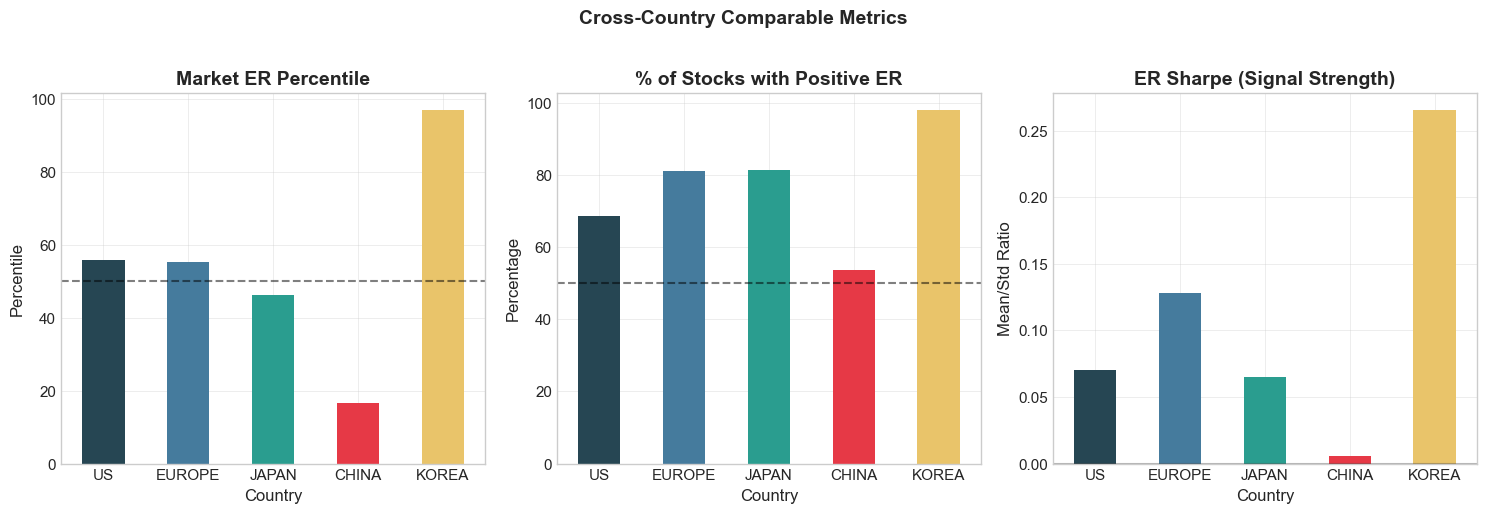

In [10]:
# Market-level expected returns comparison - WITH NORMALIZATION CONTEXT
print("="*70)
print("MARKET-LEVEL ANALYSIS")
print("="*70)
print("\n⚠️  IMPORTANT: Market ER values are NOT directly comparable across countries")
print("    because factor models have different scales/calibrations.\n")

# Raw market ERs
market_er = {}
for country in COUNTRIES:
    wmean = data['index_ER'][country]['ER_zscore'].iloc[0]
    market_er[country.upper()] = wmean

market_er_df = pd.DataFrame([market_er], index=['Weighted Mean ER (%)']).T

print("[1] MARKET ER - (z-score scales)")
print("-"*70)
display(market_er_df.style.format('{:.4f}'))

# Calculate comparable metrics using within-country distribution
print("\n[2] CROSS-COUNTRY COMPARABLE METRICS")
print("-"*70)

comparable_metrics = []
for country in COUNTRIES:
    total_stock_er = data['total_ER'][country]
    index_total_history_er = data['index_ts'][country]['index_ER']
    index_er = data['index_ER'][country]['wER'].iloc[0]

    # What percentile is the market ER within its own distribution?
    market_percentile = (index_er/100 > index_total_history_er).mean() * 100

    # Z-score of market ER within country
    market_zscore = data['index_ER'][country]['ER_zscore'].iloc[0]

    # Stock-wise
    er_values = total_stock_er['ER'].dropna()
    sh_values = total_stock_er['Sharpe'].dropna()

    # Percentage of stocks with positive ER
    pct_positive = (er_values > 0).mean() * 100

    # Spread between top and bottom quintile
    er_spread = er_values.quantile(0.8) - er_values.quantile(0.2)

    # Sharpe-like metric: mean ER / std ER
    er_sharpe = sh_values.mean()

    comparable_metrics.append({
        'Country': country.upper(),
        'Market ER Percentile': market_percentile,
        'Market ER Z-Score': market_zscore,
        '% Stocks Positive ER': pct_positive,
        'ER Dispersion (Q80-Q20)': er_spread,
        'ER Sharpe (mean/std)': er_sharpe
    })

comparable_df = pd.DataFrame(comparable_metrics).set_index('Country')
display(comparable_df.style.format({
    'Market ER Percentile': '{:.1f}',
    'Market ER Z-Score': '{:.2f}',
    '% Stocks Positive ER': '{:.1f}%',
    'ER Dispersion (Q80-Q20)': '{:.4f}',
    'ER Sharpe (mean/std)': '{:.3f}'
}).background_gradient(cmap='RdYlGn', axis=0))

print("\nInterpretation Guide:")
print("  • Market ER Percentile: Higher = More strong signal for the market relative to historical periods")
print("  • % Stocks Positive ER: Higher = More bullish signal for the market")
print("  • ER Sharpe: Higher = More consistent positive signal across stocks")

# Bar chart of comparable metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot 1: Market Percentile
ax = axes[0]
colors = [COUNTRY_COLORS[c.lower()] for c in comparable_df.index]
comparable_df['Market ER Percentile'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('Market ER Percentile', fontweight='bold')
ax.set_ylabel('Percentile')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 2: % Positive ER
ax = axes[1]
comparable_df['% Stocks Positive ER'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('% of Stocks with Positive ER', fontweight='bold')
ax.set_ylabel('Percentage')
ax.axhline(y=50, color='black', linestyle='--', alpha=0.5)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Plot 3: ER Sharpe
ax = axes[2]
comparable_df['ER Sharpe (mean/std)'].plot(kind='bar', ax=ax, color=colors)
ax.set_title('ER Sharpe (Signal Strength)', fontweight='bold')
ax.set_ylabel('Mean/Std Ratio')
ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

plt.suptitle('Cross-Country Comparable Metrics', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [11]:
# === LLM Commentary: Stock Market Analysis ===
_market_txt = "STOCK MARKET (COUNTRY-LEVEL) ANALYSIS - Current + Recent Trend\n\n"

for _c in COUNTRIES:
    _total_er  = data['total_ER'][_c]
    _idx_ts    = data['index_ts'][_c]['index_ER']
    _idx_er    = data['index_ER'][_c]['wER'].iloc[0]
    _pctile    = (_idx_er / 100 > _idx_ts).mean() * 100
    _zscore    = data['index_ER'][_c]['ER_zscore'].iloc[0]
    _pct_pos   = (_total_er['ER'].dropna() > 0).mean() * 100
    _er_sharpe = _total_er['Sharpe'].dropna().mean()
    _z4w = float(_idx_ts.iloc[-5])  if len(_idx_ts) >= 5  else float('nan')
    _z8w = float(_idx_ts.iloc[-9])  if len(_idx_ts) >= 9  else float('nan')
    _cur = float(_idx_ts.iloc[-1])
    _chg4 = _cur - _z4w
    _chg8 = _cur - _z8w
    _trend = "IMPROVING" if _chg4 > 0 else "DETERIORATING"
    _market_txt += (
        f"{_c.upper()}: Percentile={_pctile:.1f}% | Z-Score={_zscore:+.2f} | "
        f"StocksPositiveER={_pct_pos:.1f}% | AvgSharpe={_er_sharpe:.3f}\n"
        f"         ER Trend: cur={_cur:.4f} | 4w-ago={_z4w:.4f} | 8w-ago={_z8w:.4f} "
        f"| 4w-chg={_chg4:+.4f} | 8w-chg={_chg8:+.4f} ↑ {_trend}\n\n"
    )

_market_prompt = (
"당신은 지금 1.4 Stock Market Analysis 섹션 종합 해설을 작성합니다. \n"
"제공된 데이터: 5개 시장별 시장 기대수익률(ER) 현재 수준(백분위, Z-스코어) + 최근 4주/8주 변화 방향. \n\n"
"다음 흐름으로 서술하십시오: "
"최근 4~8주 기준으로 기대수익률 추세가 가장 빠르게 개선 또는 악화되고 있는 시장을 먼저 지목하십시오. "
"현재 절대 수준(백분위, Z-스코어)과 최근 추세 방향이 상충하는 시장을 경계 신호로 명시하십시오. (예: 저평가되어 있으나 추세는 계속 악화 등) "
"글로벌 동조화 여부 — 5개 시장의 ER 추세가 같은 방향으로 움직이는지, 또는 차별화되고 있는지 논의하십시오. \n"
"최근 ER 모멘텀에 근거한 지역 비중 조절 방향을 제시하십시오."
)

show_explanation(_market_txt, _market_prompt, title="1.4 Stock Market Analysis 종합 해설")


---
### 💬 1.4 Stock Market Analysis 종합 해설

1. 최근 4–8주 기준 가장 빠른 개선·악화 지표 지목.  
   - 가장 빠르게 개선된 시장은 한국으로, ER Percentile 96.8% (Z=+2.05)에서 4주 ER 변화 +0.0721·8주 +0.1004로 단기간에 급격한 모멘텀 가속 관찰됨. 이는 시장 전반의 기대수익률이 이미 높은 수준에서 추가로 상승하는 매우 강한 랠리 신호로 해석됨. 투자 시사점으로서 단기 알파 기회 존재하나 과열·포지션 집중 위험이 동반되므로 부분적 이익실현·헤지 권고.  
   - 가장 빠르게 악화되는 시장은 미국으로, 현재 Percentile 55.9% (Z=+0.23) 수준에서 4주 ER 변화 -0.0238로 최근 4주 내 수익률 기대가 하락 전환된 점이 두드러짐. 8주 관점에서는 소폭 개선(+0.0083)이 있으나 단기 추세는 분명히 약화 중으로 판단됨. 투자 시사점으로서 미국 노출은 중립 이하로 조정하고, 경기민감·소형 고베타 포지션의 방어 강화 권고.

2. 한국: 절대 수준과 모멘텀의 결합적 해석.  
   - 현재 ER의 절대적 위치(백분위·Z-스코어)와 StocksPositiveER(98.0%), AvgSharpe(0.265)가 동시에 높은 점은 펀더멘털·수급 지표가 강하게 정렬된 상태를 의미함. 4주·8주 모멘텀 모두 강한 개선을 보이며 단기 트레이드 수익 창출 가능성이 높음.  
   - 투자 시사점으로서 전술적 OW(Overweight) 권장하나, 과도한 포지션 집중(섹터·팩터 중복)을 회피하고 부분적 이익실현 규칙과 변동성·베타 헷지(옵션·현금 배치)를 병행할 것.

3. 중국: 저평가·저위치이나 개선 신호 — 경계 요인 존재.  
   - 중국은 Percentile 16.7%·Z=-1.16로 절대 기대수익률이 낮은 상태에서 StocksPositiveER 53.7%·AvgSharpe 0.005로 구조적 약세를 시사함. 다만 최근 4주·8주 ER 변화(+0.0041, +0.0111)로 개선세가 나타나고 있어 바닥 확인 단계 가능성 존재.  
   - 투자 시사점으로서 개선세를 이용한 점진적 접근(부분적 시드·퀄리티·밸류 필터 적용) 권고. 그러나 절대 수준이 낮은 만큼 모멘텀이 지속되는지(정책·유동성 확인) 확인 후 가중치 확대 권장.

4. 미국·일본: 절대 수준과 최근 추세의 엇박자 경고.  
   - 미국은 절대 수준은 중립 상회(Percentile 55.9, Z=+0.23)하나 단기 ER가 악화되는 모습으로, 이는 단기 리레이팅(차익실현) 가능성을 시사함. 일본은 Percentile 46.2·Z=-0.05로 절대적으로 중립 내외이나 최근 4주 ER가 하락(-0.0179)하여 단기 약화가 진행 중임. 흥미롭게도 일본은 StocksPositiveER 81.4%로 개별주 수준의 기대는 양호하나 지수 전반의 ER 모멘텀은 둔화 중임.  
   - 투자 시사점으로서 미국·일본은 방어적 포지셔닝(중립~UW)과 함께 이벤트 기반 리밸런싱(실적·거시·금리 신호)을 권장함.

5. 유럽: 안정적인 개선 흐름 — 선택적 기회.  
   - 유럽은 Percentile 55.3·Z=+0.17, StocksPositiveER 81.3%로 양호한 상태에서 4주·8주 ER 변화(+0.0110, +0.0059)로 개선 추세 지속. 이는 광범위한 업종에서 수익 기대가 동시 상승하는 신호로 해석됨.  
   - 투자 시사점으로서 선별적 OW 권장(실적·밸류 지표와 연계한 섹터 픽), 다만 유럽 고유의 거시·정책 리스크(에너지·정책 이벤트)에 대한 모니터링 필요.

6. 글로벌 동조화 여부·구조 분석.  
   - 5개 시장의 ER 추세는 동조화되지 않고 차별화된 양상임. 한국·중국·유럽은 개선, 미국·일본은 단기 악화로 나타나며 이는 지역별 펀더멘털·정책·수급의 비동기적 전개를 반영함. 결과적으로 글로벌 동시 랠리보다는 지역별 전술적 리밸런싱 기회가 더 많음.  
   - 투자 시사점으로서 포트폴리오는 지역별 ER 모멘텀을 반영한 전술적 재분배가 유효하며, 전역적 리스크 이벤트(금리·유동성 충격)를 대비한 크로스마켓 헷지 유지 필요.

7. 최근 ER 모멘텀에 근거한 권장 지역 비중 조정.  
   - 권장 배치(단기 전술적 관점): 한국 — Overweight(단, 부분적 차익실현 및 헷지 병행), 중국 — Moderate Overweight(점진적 확대, 정책·펀더멘털 확인), 유럽 — Modest Overweight(선별적 섹터), 미국 — Neutral→Underweight(단기 악화 반영하여 비중 축소), 일본 — Neutral→Underweight(모멘텀 약화에 따라 축소).  
   - 위험통제 가이드: 각 지역 비중 확대 시 포지션 크기 제한(사전 손실 한도), 상관 변화·유동성 지표 실시간 점검, 이벤트 리스크(금리·정책 발표) 전후의 방어적 리밸런싱 규칙 적용 권고.

결론: 최근 4–8주 ER 모멘텀은 지역별로 뚜렷한 차별화를 보이며, 한국의 과도한 상승과 중국의 바닥 탈피 가능성이 가장 눈에 띔. 이에 따라 단기적으로는 지역별 모멘텀을 활용한 전술적 비중 조정이 바람직하나, 절대 수준(백분위·Z-스코어)과 모멘텀의 불일치 지점에서는 신중한 점진적 접근과 엄격한 리스크 관리를 병행할 것.

---

---
## Factor Analysis

### Factor Expected Returns

In [12]:
# Create factor returns comparison table - RAW and NORMALIZED
print("="*70)
print("FACTOR RETURNS BY COUNTRY")
print("="*70)
print("    Use Z-Score for valid cross-country comparisons.\n")

# Z-Score normalized (within each country)
factor_zscore_df = pd.DataFrame()
for country in COUNTRIES:
    fr = data['factor_ER'][country]['ER_zscore']
    factor_zscore_df[country.upper()] = fr
factor_zscore_df = factor_zscore_df.T

print("\n[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)")
print("-"*70)
display(factor_zscore_df.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country factor comparison using z-scores
print("\n[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)")
print("-"*70)
print("Which factors are consistently strong/weak across all markets:")
factor_strength = factor_zscore_df.mean().sort_values(ascending=False)
for factor, zscore in factor_strength.items():
    strength = "STRONG ↑" if zscore > 0.5 else ("WEAK ↓" if zscore < -0.5 else "NEUTRAL →")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {factor:5}: {zscore:+.2f} {strength} {bar}")

FACTOR RETURNS BY COUNTRY
    Use Z-Score for valid cross-country comparisons.


[2] Z-SCORE NORMALIZED - Comparable across countries (0 = country average)
----------------------------------------------------------------------


,BM,HML,INV,MOM,OP,SMB
US,0.23,0.33,-0.23,-2.04,-0.11,0.55
EUROPE,0.18,-0.59,0.24,-2.89,-0.17,0.35
JAPAN,-0.04,-1.03,-1.51,0.42,-1.16,-0.37
CHINA,-1.12,0.20,0.47,0.82,-1.10,0.05
KOREA,2.22,-0.12,-0.59,3.52,-0.08,-4.64



[4] CROSS-COUNTRY FACTOR STRENGTH (Z-Score Average)
----------------------------------------------------------------------
Which factors are consistently strong/weak across all markets:
  BM   : +0.29 NEUTRAL → ██
  MOM  : -0.03 NEUTRAL → 
  HML  : -0.24 NEUTRAL → ██
  INV  : -0.32 NEUTRAL → ███
  OP   : -0.52 WEAK ↓ █████
  SMB  : -0.82 WEAK ↓ ████████


### Factor Premium Comparison

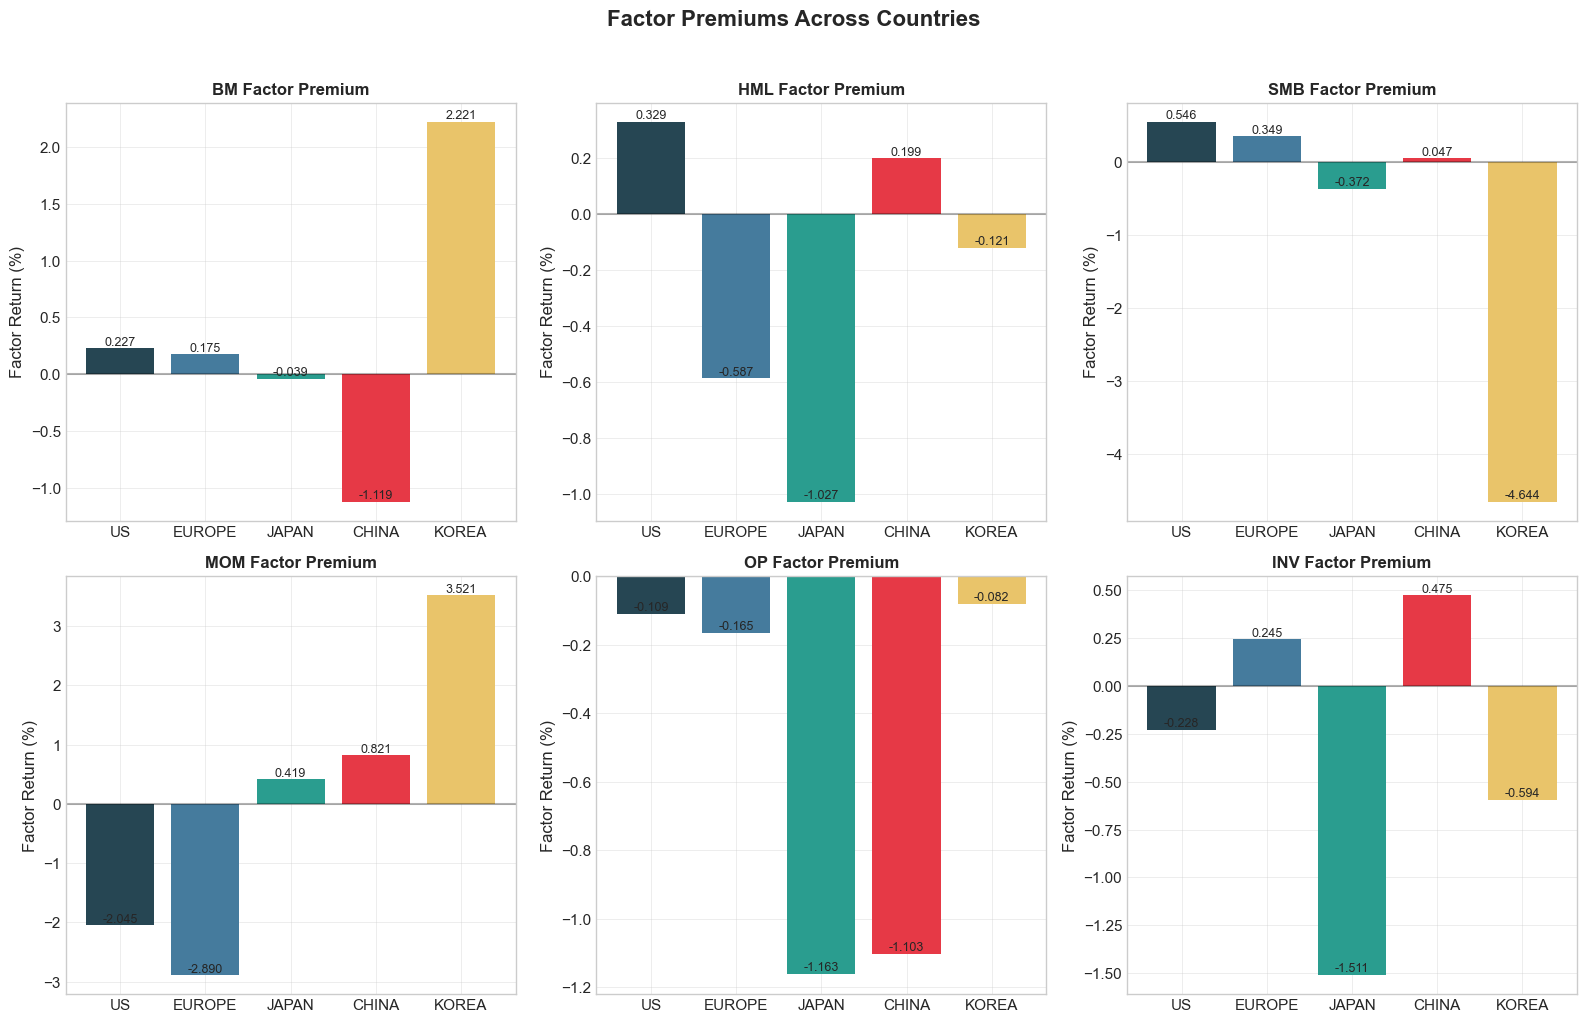

In [13]:
# Factor premium comparison across countries
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

factors = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']

for idx, factor in enumerate(factors):
    ax = axes[idx]
    factor_vals = []

    for country in COUNTRIES:
        fr = data['factor_ER'][country]['ER_zscore']
        if factor in fr.index:
            factor_vals.append(fr.loc[factor])
        else:
            factor_vals.append(0)

    colors = [COUNTRY_COLORS[c] for c in COUNTRIES]
    bars = ax.bar([c.upper() for c in COUNTRIES], factor_vals, color=colors)
    ax.axhline(y=0, color='black', linestyle='-', alpha=0.3)
    ax.set_title(f'{factor} Factor Premium', fontsize=12, fontweight='bold')
    ax.set_ylabel('Factor Return (%)')

    # Add value labels
    for bar, val in zip(bars, factor_vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.suptitle('Factor Premiums Across Countries', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [14]:
# === LLM Commentary: Factor Analysis ===
_factor_a_txt = "FACTOR ANALYSIS \u2014 Expected Returns + Cross-Country Premiums\n\n"

# Part A: Factor ER (Z-score + 4w trend)
_factor_a_txt += "=== PART A: FACTOR EXPECTED RETURNS (Z-Score + 4-Week Trend) ===\n\n"
for _c in COUNTRIES:
    _fts   = data['factor_ts'][_c]
    _fER_z = data['factor_ER'][_c]['ER_zscore']
    _factor_a_txt += f"{'='*35}\n{_c.upper()}\n{'='*35}\n"
    _factor_a_txt += f"{'Factor':6} | Z-Score | cur ER  | 4w-ago  | 4w-chg | trend\n"
    for _f in _fER_z.index:
        _col = f"{_f}_ER"
        _z   = _fER_z.get(_f, float('nan'))
        if _col in _fts.columns and len(_fts) >= 5:
            _cur  = float(_fts[_col].iloc[-1])
            _4w   = float(_fts[_col].iloc[-5])
            _chg  = _cur - _4w
            _dir  = "↑" if _chg > 0 else "↓"
        else:
            _cur = _4w = _chg = float('nan')
            _dir = "?"
        _factor_a_txt += f"  {_f:5}: z={_z:+.2f} | {_cur:.4f} | {_4w:.4f} | {_chg:+.4f} {_dir}\n"
    _factor_a_txt += "\n"

# Global 4w average
_factor_a_txt += "GLOBAL 4-WEEK FACTOR ER CHANGE (avg across countries):\n"
_f_changes = {}
for _f in data['factor_ER'][COUNTRIES[0]]['ER_zscore'].index:
    _col = f"{_f}_ER"
    _chgs = []
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        if _col in _fts.columns and len(_fts) >= 5:
            _chgs.append(float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5]))
    if _chgs:
        _f_changes[_f] = sum(_chgs) / len(_chgs)
for _f, _chg in sorted(_f_changes.items(), key=lambda x: -x[1]):
    _dir = "↑ RISING" if _chg > 0 else "↓ FALLING"
    _factor_a_txt += f"  {_f:5}: avg 4w-chg = {_chg:+.4f}  {_dir}\n"

# Part B: Cross-country factor premiums
_factor_a_txt += "\n=== PART B: CROSS-COUNTRY FACTOR PREMIUMS (Z-Score + 4-Week Direction) ===\n\n"
_factors_list = ['BM', 'HML', 'SMB', 'MOM', 'OP', 'INV']
for _f in _factors_list:
    _col = f"{_f}_ER"
    _factor_a_txt += f"{_f}:\n"
    for _c in COUNTRIES:
        _fts = data['factor_ts'][_c]
        _z   = data['factor_ER'][_c]['ER_zscore'].get(_f, float('nan'))
        if _col in _fts.columns and len(_fts) >= 5:
            _chg = float(_fts[_col].iloc[-1]) - float(_fts[_col].iloc[-5])
            _dir = "↑" if _chg > 0 else "↓"
        else:
            _chg, _dir = float('nan'), "?"
        _factor_a_txt += f"  {_c.upper():8}: z={_z:+.2f}  4w-chg={_chg:+.4f} {_dir}\n"
    _factor_a_txt += "\n"

_factor_prompt = (
"당신은 지금 1.5 Factor Analysis 섹션 종합 해설을 작성합니다. \n\n"
"제공된 데이터는 두 파트로 구성됩니다: "
"Part A — 5개 시장 × 7개 팩터의 현재 Z-스코어 기대수익률 + 최근 4주 변화 방향 "
"Part B — 6개 팩터별 5개 국가 Z-스코어 + 4주 변화 방향 (국가 간 비교) \n"
"다음 흐름으로 서술하십시오: "
"현재 기대수익률 모멘텀이 가장 강한 팩터(전 세계적으로 4주 연속 상승 추세)를 최우선으로 서술하십시오. "
"Z-스코어는 높으나 최근 4주 기대수익률이 하락 중인 팩터를 지적하십시오. (포지션 혼잡 또는 반전 가능성 경고) "
"국가 간 팩터 프리미엄 차별화가 가장 큰 팩터를 식별하여, 가장 매력적인 [국가-팩터] 조합을 제시하십시오. "
"Part A와 Part B를 통합하여 향후 4주간의 팩터 포지셔닝 방향을 종합 의견으로 제시하십시오. \n"
"4주 변화 방향(↑/↓)을 핵심 신호로 삼고, Z-스코어는 맥락으로만 활용하십시오. "
)

show_explanation(_factor_a_txt, _factor_prompt, title="1.5 Factor Analysis 종합 해설")


---
### 💬 1.5 Factor Analysis 종합 해설

1. 전 세계적으로 가장 강한 4주 모멘텀 팩터 식별 및 해석.  
   - 도입: 최근 4주 기준으로 전 세계에서 가장 일관되게 상승한 팩터는 MOM(모멘텀)임.  
   - 근거·해석: 글로벌 4주 평균 변화가 +0.0157으로 모든 팩터 중 최고 수준이며, 특히 한국(+0.0583), 유럽(+0.0122), 중국(+0.0044), 일본(+0.0038)에서 상승이 관찰되어 지역적으로도 광범위한 강화. 이는 최근 단기 트렌드가 모멘텀 전략에 우호적임을 의미하며, 일부 지역(미국 제외)에서 모멘텀이 시장 베타와 동조화된 형태로 확산되고 있음을 시사.  
   - 투자시사점: 향후 4주 전술적 관점에서 모멘텀 롱을 우선 고려하되, 지역별 편차를 반영하여 한국·중국·일본·유럽 중심의 모멘텀 익스포저 확대를 권고(미국 모멘텀은 정체).

2. Z-스코어는 높으나 최근 4주 기대수익률이 하락 중인 팩터(혼잡·반전 경고).  
   - 도입: 팩터의 절대 매력도(Z-스코어)와 단기 모멘텀(4주 변화)이 엇박자를 보이는 경우 과도한 포지셔닝·반전 위험 발생 가능.  
   - 근거·해석: 대표적 사례로 미국 SMB(z=+0.55, 4w-chg=-0.0215) 및 미국 HML(z=+0.33, 4w-chg=-0.0213), 미국 BM(z=+0.23, 4w-chg=-0.0238)가 있음. 이들은 과거(국가 내 기준) 상대적 매력이 높은 상태에서 최근 4주에 기대수익이 후퇴한 패턴으로, 포지션이 혼잡해져 단기 반전 리스크가 확대될 가능성 존재.  
   - 투자시사점: 이러한 팩터에 대해선 신규 레버리지 확대를 피하고, 기존 롱 포지션의 부분 차익실현 및 리스크 제한(손절·헤지) 규칙 적용 권고.

3. 국가 간 팩터 프리미엄 차별화가 가장 큰 팩터 및 최우수 [국가-팩터] 조합.  
   - 도입: 국가 간 Z-스코어 분산이 큰 팩터는 지역별 전략 차별화의 기회를 제공.  
   - 근거·해석: MOM과 SMB가 국가간 분산이 가장 큼(MOM z 범위 약 -2.89~+3.52, SMB z 범위 약 -4.64~+0.55). 특히 MOM은 한국(+3.52, 4w +0.0583)·한국 BM(+2.22, 4w +0.0689)에서 절대·단기 모멘텀이 동시 우수함. 중국도 MOM(+0.82, 4w +0.0044)·HML(+0.20, 4w +0.0028)이 개선 국면.  
   - 투자시사점(추천 조합): 1) Korea–MOM(최우선): 강한 Z·강한 4주 상승으로 단기 알파 우선순위. 2) Korea–BM(보조 우선): BM과 MOM의 동행에 따른 베타·모멘텀 복합 수혜 가능성(단, 집중 리스크 유의). 3) China–MOM 또는 China–HML: 바닥 구간에서 모멘텀·가치 동시 회복 신호 활용. 4) US–OP(전술적 헤지): 미국 OP는 4주 변화 +0.0268로 회복 신호, 상대적 저평가성으로 대체적 방어 역할 기대.

4. Part A·B 통합: 향후 4주간 팩터 포지셔닝 종합 의견.  
   - 도입: 글로벌 평균 및 국가별 4주 변화(↑/↓)를 결합한 단기 포지셔닝 방향 제시.  
   - 근거·해석: 전세계적 평균으로는 MOM·BM·HML·INV·OP이 상승, SMB만 하락 추세. 지역적으로는 한국(강한 BM·MOM 상승), 중국(모멘텀·가치 동시 강화), 유럽·일본(선택적 모멘텀·BM 강화), 미국(일부 팩터 단기 후퇴)이 확인됨. 또한 Part B의 국가별 프리미엄 분포는 동일 팩터라도 노출을 국별로 차별화해야 하는 필요성(예: MOM은 한국·중국·일본 우수, 미국 약세)을 강조.  
   - 투자시사점: 향후 4주간 기본 포지셔닝은 MOM OW(지역선택적: Korea/China/Japan/Europe), BM 선택적 OW( Korea/Europe/China ), SMB 전면 UW(글로벌 회피), OP·INV는 선별적·전술적 OW(특히 US OP), HML은 지역별로 소폭 OW(예: Korea/China)로 권고.  

5. 리스크·운용 가이드라인(전술적 제약).  
   - 도입: 단기 팩터 전략은 급변하는 상관관계·집중 위험에 취약.  
   - 권고: 1) Korea 내 BM·MOM 동시 노출 시 포지션 크기 제한 및 섹터·종목 분산 적용. 2) SMB의 글로벌 하락세에 따라 소형주 팩터 기반 레버리지 회피. 3) Z-스코어 높으나 4주 하락 팩터(예: US SMB/HML)는 트레이드 진입 시 축소·부분 환매 규칙 적용. 4) 포트폴리오 리스크모델에 최근 8주 상관 변화 반영(동적 가중치) 필수.

6. 결론 요약.  
   - 결론: 단기(4주) 관점에서 MOM이 가장 강한 상승 모멘텀을 보이며, 특히 Korea–MOM·Korea–BM이 최우수 기회로 식별됨. 반면 SMB는 전세계적으로 약화 중으로 회피 권고. Z-스코어가 높으나 최근 4주 하락하는 팩터는 혼잡·반전 위험을 경계하며 보수적 리밸런싱과 엄격한 리스크 통제 필요.

---

---
## Sector Analysis

### Sector Factor Exposures

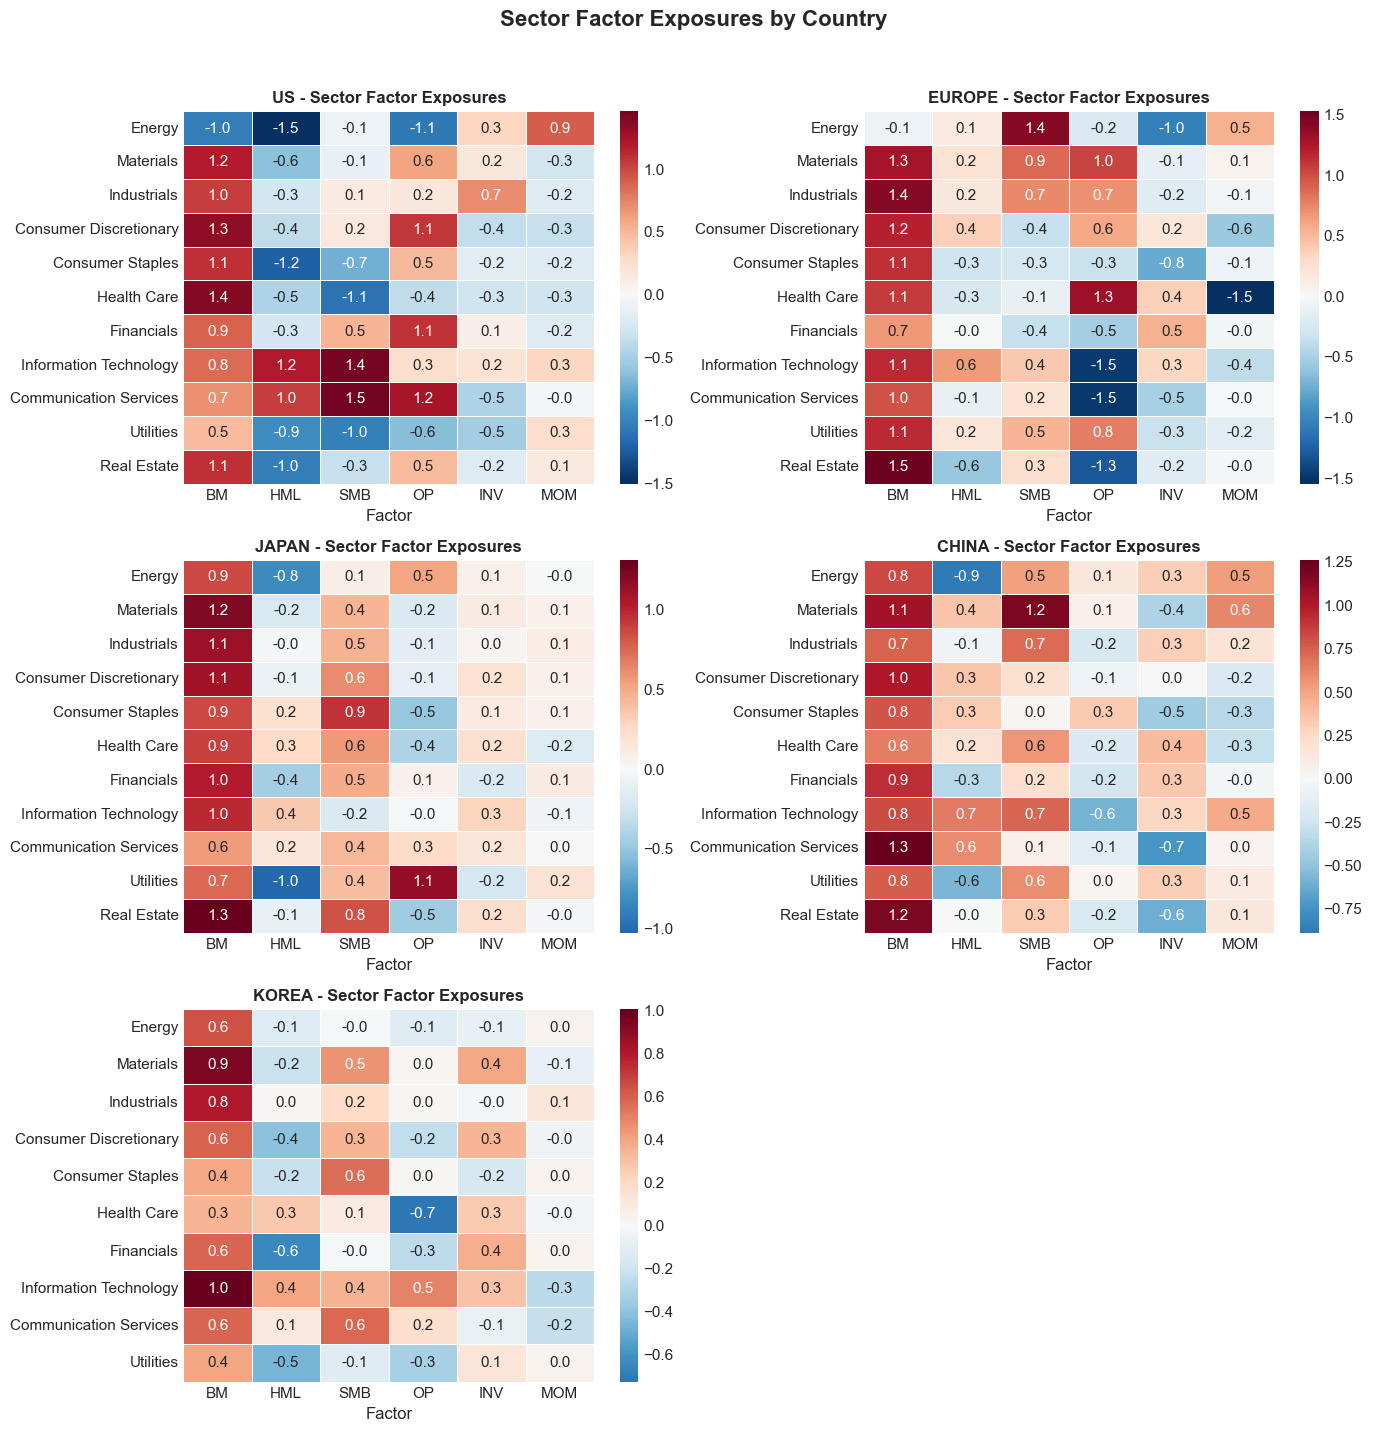

In [15]:
# Sector factor exposure heatmaps
factor_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']

fig, axes = plt.subplots(3, 2, figsize=(14, 14))
axes = axes.flatten()

for idx, country in enumerate(COUNTRIES):
    ax = axes[idx]
    ind_er = data['sector_ER'][country].copy()

    # Get sector names as index
    if 'Sector' in ind_er.columns:
        ind_er = ind_er.set_index('Sector')
    elif 'industry' in ind_er.columns:
        ind_er['Sector'] = ind_er['industry'].astype(str).map(SECTOR_NAMES)
        ind_er = ind_er.set_index('Sector')

    # Get available factor columns
    available_factors = [col for col in factor_cols if col in ind_er.columns]

    if available_factors:
        plot_data = ind_er[available_factors].dropna(how='all')
        plot_data.columns = [c.replace('beta_', '').upper() for c in plot_data.columns]

        sns.heatmap(plot_data, annot=True, fmt='.1f', cmap='RdBu_r',
                    center=0, ax=ax, linewidths=0.5)
        ax.set_title(f'{country.upper()} - Sector Factor Exposures', fontsize=12, fontweight='bold')
        ax.set_xlabel('Factor')
        ax.set_ylabel('')
    else:
        ax.text(0.5, 0.5, 'No factor data available', ha='center', va='center')
        ax.set_title(f'{country.upper()}')

axes[5].axis('off')
plt.suptitle('Sector Factor Exposures by Country', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### Sector Expected Returns

In [16]:
# Sector Expected Returns comparison - RAW and NORMALIZED
print("="*90)
print("SECTOR EXPECTED RETURNS BY COUNTRY")
print("="*90)
print("\n⚠️  NOTE: Raw ER values have different scales across countries.")
print("    Use Z-Score for valid cross-country sector comparisons.\n")

# Z-Score normalized sector ERs
sector_zscore_comparison = pd.DataFrame()
for country in COUNTRIES:
    ind_er = data['sector_ER'][country].copy()
    ind_er = ind_er.set_index('Sector')
    sector_zscore_comparison[country.upper()] = ind_er['ER_zscore']

print("\n[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)")
print("-"*70)
display(sector_zscore_comparison.style.format('{:.2f}').background_gradient(cmap='RdYlGn', axis=None))

# Cross-country sector analysis
print("\n[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)")
print("-"*70)
sector_global_strength = sector_zscore_comparison.mean(axis=1).sort_values(ascending=False)
for sector, zscore in sector_global_strength.items():
    strength = "OVERWEIGHT" if zscore > 0.3 else ("UNDERWEIGHT" if zscore < -0.3 else "NEUTRAL")
    bar = "█" * int(abs(zscore) * 10)
    print(f"  {str(sector):25}: {zscore:+.2f} {strength} {bar}")

SECTOR EXPECTED RETURNS BY COUNTRY

⚠️  NOTE: Raw ER values have different scales across countries.
    Use Z-Score for valid cross-country sector comparisons.


[2] Z-SCORE NORMALIZED - Comparable (0 = average sector in country)
----------------------------------------------------------------------


,US,EUROPE,JAPAN,CHINA,KOREA
Sector,,,,,
Energy,-0.26,0.07,0.05,-2.88,0.71
Materials,-0.33,0.24,0.01,-1.34,1.17
Industrials,0.02,0.11,-0.03,-1.24,1.36
Consumer Discretionary,0.02,-0.06,-0.17,-2.02,1.73
Consumer Staples,-0.72,-0.25,-0.31,-1.56,0.90
Health Care,-0.51,-0.50,-0.28,-0.26,-0.28
Financials,-0.03,0.35,0.02,-1.05,1.03
Information Technology,0.36,0.46,0.03,-0.21,2.32
Communication Services,0.65,0.01,-0.14,-1.09,0.72



[4] GLOBAL SECTOR ATTRACTIVENESS (Average Z-Score across countries)
----------------------------------------------------------------------
  Information Technology   : +0.59 OVERWEIGHT █████
  Financials               : +0.06 NEUTRAL 
  Industrials              : +0.05 NEUTRAL 
  Communication Services   : +0.03 NEUTRAL 
  Materials                : -0.05 NEUTRAL 
  Consumer Discretionary   : -0.10 NEUTRAL 
  Real Estate              : -0.14 NEUTRAL █
  Utilities                : -0.31 UNDERWEIGHT ███
  Health Care              : -0.36 UNDERWEIGHT ███
  Consumer Staples         : -0.39 UNDERWEIGHT ███
  Energy                   : -0.46 UNDERWEIGHT ████


### Top Equities by country

In [17]:
# Top 10 stocks by Expected Return for each country
print("="*90)
print("TOP 10 STOCKS BY EXPECTED RETURN (Each Country)")
print("="*90)

for country in COUNTRIES:
    print(f"\n{'-'*70}")
    print(f"{country.upper()}")
    print("-"*70)

    top_bot = data['top_bot'][country]
    top_bot['Sector'] = top_bot['sector'].map(lambda x: SECTOR_NAMES[x], na_action='ignore')
    # Get top 10 (highest ER)
    if 'ER' in top_bot.columns:
        top10 = top_bot.nlargest(10, 'ER')[['instrument', 'Name', 'Sector', 'ER', 'Vol', 'Sharpe', 'mktval']]
        top10.columns = ['ISIN', 'Name', 'Sector', 'Expected Return(%)', 'Vol(%)', 'Sharpe(X)', 'Market Cap(Local mn)']
        top10 = top10.style.format({
            'Expected Return(%)': '{:.2f}',
            'Vol(%)': '{:.2f}',
            'Sharpe(X)': '{:.2f}',
            'Market Cap(Local mn)': '{:,.0f}',
        })
        display(top10)

TOP 10 STOCKS BY EXPECTED RETURN (Each Country)

----------------------------------------------------------------------
US
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
3,US57776J1007,Maxlinear Inc,Info Tech,21.11,39.84,0.53,"8,341"
0,US4581401001,Intel Corp,Info Tech,11.03,18.99,0.58,"627,340"
16,US0079031078,Advanced Micro Devices Inc,Info Tech,8.18,18.19,0.45,"737,473"
9,US52476L1098,Legence Corp,nan,8.09,15.80,0.51,"6,589"
15,SG9999000020,Flex Ltd,Info Tech,7.95,17.51,0.45,"51,870"
8,US5738741041,Marvell Technology Inc,Info Tech,7.57,14.65,0.52,"148,231"
14,US9255501051,Viavi Solutions Inc,Info Tech,6.64,14.55,0.46,"11,790"
4,US55405W1045,MYR Group Inc,Industrials,6.25,11.86,0.53,"6,691"
18,US9581021055,Western Digital Corp,Info Tech,6.12,14.24,0.43,"164,220"
17,US24703L2025,Dell Technologies Inc,Info Tech,6.07,13.82,0.44,"150,767"



----------------------------------------------------------------------
EUROPE
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
3,DE000A0WMPJ6,Aixtron SE,Info Tech,7.50,14.44,0.52,"5,705"
0,FI0009000681,Nokia Oyj,Info Tech,6.38,10.76,0.59,"58,425"
11,NL0000226223,STMicroelectronics NV,Info Tech,5.89,13.62,0.43,"32,211"
10,NL0012866412,BE Semiconductor Industries NV,Info Tech,5.87,13.46,0.44,"18,811"
7,DE0006070006,Hochtief AG,Industrials,5.42,11.59,0.47,"8,504"
2,IT0004176001,Prysmian SpA,Industrials,5.40,9.79,0.55,"45,068"
6,DE0006231004,Infineon Technologies AG,Info Tech,5.25,11.10,0.47,"81,095"
5,ES0125220311,Acciona SA,Utilities,5.01,10.57,0.47,"6,132"
13,IT0005366767,Nexi SpA,Financials,4.84,11.41,0.42,"2,208"
9,CH0030380734,Huber+Suhner AG,nan,4.82,10.62,0.45,"4,338"



----------------------------------------------------------------------
JAPAN
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
10,JP3236330001,Kioxia Holdings Corp,nan,5.59,27.51,0.20,"8,337,706"
0,JP3888400003,Mitsui Kinzoku Co Ltd,Materials,4.61,17.84,0.26,"2,681,444"
13,JP3827200001,Furukawa Electric Co Ltd,Industrials,4.00,20.31,0.20,"2,983,365"
19,JP3148800000,Ibiden Co Ltd,Info Tech,3.86,20.52,0.19,"3,872,999"
1,JP3811000003,Fujikura Ltd,Industrials,3.57,14.86,0.24,"11,442,121"
6,JP3368000000,Resonac Holdings Corp,Materials,2.86,13.04,0.22,"2,924,517"
5,JP3407400005,Sumitomo Electric Industries Ltd,Consumer Disc.,2.77,12.43,0.22,"8,668,671"
18,JP3571800006,Tokyo Ohka Kogyo Co Ltd,Materials,1.97,10.39,0.19,"1,130,601"
4,JP3695200000,NGK Insulators Ltd,Industrials,1.89,8.33,0.23,"1,520,385"
14,JP3635000007,Toyota Tsusho Corp,Industrials,1.82,9.37,0.19,"4,668,464"



----------------------------------------------------------------------
CHINA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
3,CNE100001T72,Yangtze Optical Fibre and Cable Joint Stock Ltd Co,nan,6.49,32.32,0.20,"236,489"
0,CNE100005VF9,Yuanjie Semiconductor Technology Co Ltd,nan,5.09,20.03,0.25,"86,856"
2,CNE100002615,Eoptolink Technology Inc Ltd,Info Tech,4.88,21.35,0.23,"439,546"
1,CNE100001CY9,Zhongji Innolight Co Ltd,Info Tech,4.61,18.61,0.25,"706,918"
5,CNE1000048G6,RemeGen Co Ltd,nan,4.28,23.04,0.19,"54,587"
9,CNE1000055X6,Dosilicon Co Ltd,nan,4.10,25.28,0.16,"42,609"
4,CNE100000N79,Suzhou Dongshan Precision Manufacturing Co Ltd,Info Tech,4.03,20.21,0.20,"263,195"
12,CNE100001XQ1,Suzhou TFC Optical Communication Co Ltd,Info Tech,4.02,26.10,0.15,"135,899"
7,CNE1000020V4,Victory Giant Technology HuiZhou Co Ltd,Info Tech,3.14,17.90,0.18,"213,550"
18,CNE100005GP9,Shenzhen Techwinsemi Technology Co Ltd,nan,2.99,21.07,0.14,"72,799"



----------------------------------------------------------------------
KOREA
----------------------------------------------------------------------


,ISIN,Name,Sector,Expected Return(%),Vol(%),Sharpe(X),Market Cap(Local mn)
2,KR7402340004,SK Square Co Ltd,Industrials,14.40,21.73,0.66,"98,241,129"
1,KR7000660001,SK Hynix Inc,Info Tech,12.35,17.09,0.72,"942,410,606"
7,KR7006800007,Mirae Asset Securities Co Ltd,Financials,10.37,17.96,0.58,"21,960,706"
11,KR7001440007,Taihan Cable & Solution Co Ltd,Industrials,10.23,18.43,0.56,"7,799,347"
5,KR7298040007,Hyosung Heavy Industries Corp,Industrials,9.96,16.28,0.61,"20,948,401"
3,KR7034730002,SK Inc,Industrials,9.77,15.60,0.63,"26,485,956"
18,KR7062040001,Sanil Electric Co Ltd,Industrials,9.58,18.44,0.52,"3,038,554"
4,KR7009150004,Samsung Electro-Mechanics Co Ltd,Info Tech,9.58,15.64,0.61,"52,475,692"
10,KR7010120004,LS Electric Co Ltd,Industrials,9.42,16.95,0.56,"23,967,589"
19,KR7000150003,Doosan Corp,Industrials,9.38,18.26,0.51,"15,976,119"


In [18]:
# === LLM Commentary: Sector Analysis ===
_sector_full_txt = "SECTOR ANALYSIS \u2014 Factor Exposures + Expected Returns + Top Equities\n\n"

# Part A: Sector factor betas
_sector_full_txt += "=== PART A: SECTOR FACTOR EXPOSURES (structural betas) ===\n\n"
_beta_cols = ['beta_bm', 'beta_hml', 'beta_smb', 'beta_op', 'beta_inv', 'beta_mom']
for _c in COUNTRIES:
    _ie = data['sector_ER'][_c].copy()
    if 'Sector' in _ie.columns:
        _ie = _ie.set_index('Sector')
    _avail = [col for col in _beta_cols if col in _ie.columns]
    if _avail:
        _exp = _ie[_avail].dropna(how='all').copy()
        _exp.columns = [col.replace('beta_', '').upper() for col in _exp.columns]
        _sector_full_txt += f"{'='*30}\n{_c.upper()}\n{'='*30}\n"
        _sector_full_txt += _exp.round(2).to_string() + "\n\n"

# Part B: Sector expected return Z-scores + 4-week trend
_sector_full_txt += "=== PART B: SECTOR EXPECTED RETURNS (Z-Score + 4-Week Trend) ===\n\n"
_sec_zscore = pd.DataFrame()
for _c in COUNTRIES:
    _ie = data['sector_ER'][_c].copy().set_index('Sector')
    _sec_zscore[_c.upper()] = _ie['ER_zscore']
_sector_full_txt += "Current Z-Score by Country:\n" + _sec_zscore.round(2).to_string() + "\n\n"

_sec_trend = pd.DataFrame()
for _c in COUNTRIES:
    _sts = data['sector_ts'][_c]
    _trends = {}
    for _col in _sts.columns:
        if _col.endswith('_ER') and len(_sts) >= 5:
            _sec_code = _col.replace('_ER', '')
            _sec_name = SECTOR_NAMES.get(_sec_code, _sec_code)
            _chg = float(_sts[_col].iloc[-1]) - float(_sts[_col].iloc[-5])
            _trends[_sec_name] = _chg
    if _trends:
        _sec_trend[_c.upper()] = pd.Series(_trends)
if not _sec_trend.empty:
    _sector_full_txt += "4-Week Sector ER Change by Country:\n"
    _sector_full_txt += _sec_trend.round(4).to_string()
    _sector_full_txt += "\n\nGlobal Average 4-Week Sector ER Change (ranked):\n"
    _global_chg = _sec_trend.mean(axis=1).sort_values(ascending=False)
    for _sec, _v in _global_chg.items():
        _arrow = "↑" if _v > 0 else "↓"
        _sector_full_txt += f"  {str(_sec):28}: {_v:+.4f} {_arrow}\n"

# Part C: Top 20 equities per country
_sector_full_txt += "\n=== PART C: TOP 20 EQUITIES BY EXPECTED RETURN ===\n\n"
for _c in COUNTRIES:
    _tb = data['top_bot'][_c].copy()
    _tb['SectorName'] = _tb['sector'].map(lambda x: SECTOR_NAMES.get(str(x), str(x)))
    if 'ER' in _tb.columns:
        _top20 = _tb.nlargest(20, 'ER')
        _sector_full_txt += f"{'='*40}\n{_c.upper()}\n{'='*40}\n"
        for _, _row in _top20.iterrows():
            _name = str(_row.get('Name', _row.get('instrument', '')))[:30]
            _sec  = str(_row.get('SectorName', ''))[:20]
            _er   = _row.get('ER', 0)
            _sh   = _row.get('Sharpe', 0)
            _sector_full_txt += f"  {_name:30} | {_sec:20} | ER={_er:.2f}% | Sharpe={_sh:.2f}\n"
        _sector_full_txt += "\n"

_sector_prompt = (
"당신은 지금 1.6 Sector Analysis 섹션 종합 해설을 작성합니다. 이것은 보고서의 마지막 섹션입니다. 제공된 데이터는 세 파트로 구성됩니다: "
"Part A — 5개 시장별 섹터의 팩터 베타(구조적 노출도) "
"Part B — 현재 섹터 기대수익률(ER) Z-스코어 + 최근 4주 변화 방향 "
"Part C — 시장별 기대수익률 상위 20개 종목(섹터, ER, Sharpe 포함)\n"
"다음 흐름으로 서술하십시오: "
"이전 섹션(1.5 Factor Analysis)에서 식별된 상승 팩터들을 연계하여, 현재 가장 수혜 가능한 섹터를 선별하십시오. (예: 팩터 베타 × 팩터 모멘텀의 교차점에서 투자 기회 발굴) "
"섹터 기대수익률 4주 변화 기준으로 가장 빠르게 개선/악화되는 섹터를 지목하고, 이것이 글로벌 공통 현상인지 특정 국가의 현상인지 구분하십시오. "
"상위 20개 종목 구성이 섹터 로테이션 분석과 일치하는지 점검하고, 불일치가 있다면 그 시사점을 논의하십시오.\n"
"보고서 전체를 통합하는 결론 단락을 작성하십시오: "
"가장 명확한 근거가 있는 단기 투자 기회 1가지 "
"가장 주의해야 할 리스크 요인 1가지\n"
"이 섹션은 보고서의 결론부이므로, 앞선 모든 섹션의 분석을 자연스럽게 수렴시키는 서술로 마무리하십시오. "
)

show_explanation(_sector_full_txt, _sector_prompt, title="1.6 Sector Analysis 종합 해설")


---
### 💬 1.6 Sector Analysis 종합 해설

1. 요약 및 맥락 연결(1.5 Factor Analysis와 연계).  
   - 도입: 1.5에서 식별된 핵심 신호는 전세계적 모멘텀(MOM)과 베타(BM)의 단기 강화(4주 기준)였음. 섹터 관점에서는 이들 상승 팩터에 구조적 노출(BM·MOM 베타)이 높은 섹터가 직접적 수혜 대상이 됨. 본 섹션은 팩터 베타(Part A)와 섹터 ER의 최근 모멘텀(Part B), 및 상위 종목 구성(Part C)을 교차 검증하여 단기(4주) 투자 우선순위를 제시함.

2. 팩터 모멘텀 × 섹터 베타 교차로 도출된 수혜 섹터(우선순위).  
   - 도입: 모멘텀(MOM)·베타(BM) 상승이 관측되는 지역에서, 해당 팩터에 높은 베타를 가진 섹터 우선 수혜 예상.  
   - 근거·해석: Korea는 BM·MOM 모두 강하게 상승(1.5 참조)하고, 섹터 베타에서 Information Technology(BM=1.00)와 Industrials(BM=0.80, MOM=0.12)가 BM·MOM 수혜군에 해당함. 또한 Korea의 섹터별 4주 ER 변화는 Info Tech +0.0947, Consumer Disc +0.0666, Industrials +0.0578로 IT·산업재의 급속 개선이 명확함. China에서도 Materials(BM=1.05, MOM=0.61)와 Information Technology(BM=0.82, MOM=0.47)가 BM·MOM 동시 수혜 가능. 글로벌 평균으로는 Energy·Materials·Health Care·Info Tech의 4주 ER 개선이 상위권에 위치하므로, 이들 섹터는 지역별로 선별적 OW(오버웨이트) 대상임.  
   - 투자시사점: 우선순위는 Korea — Industrials·Information Technology(전술적 OW), China — Materials·Information Technology(선별적 OW), 글로벌 관점에서는 Energy·Materials를 전술적 OW로 고려. 다만 Korea의 IT·Industrial 노출은 이미 과열 가능성(ER·Z 높음)을 반영하므로 포지션 크기 관리 필수.

3. 4주 섹터 ER 변화로 본 급속 개선·악화 지점 및 범위(글로벌 공통성 여부).  
   - 도입: 4주 ER 변화가 가장 큰 섹터를 지목하고, 그것이 글로벌 공통 현상인지 특정 국가 현상인지 구분.  
   - 근거·해석: 가장 빠르게 개선되는 섹터(국가별 절대값 기준)는 Korea Info Tech(+0.0947), Korea Consumer Disc(+0.0666), Korea Industrials(+0.0578)로서 이는 한국 특유의 강한 팩터 모멘텀에 기인한 국내 현상임. 반면 글로벌 평균 기준으로는 Energy(+0.0135)·Materials(+0.0132)·Health Care(+0.0119)·Info Tech(+0.0113)가 상위 개선섹터로, Energy·Materials는 다수 지역에서 동시 개선(미국·유럽·중국·한국 등)으로 비교적 글로벌 공통 현상에 해당함. 가장 악화되는 섹터는 Consumer Discretionary(글로벌 avg -0.0029)와 Communication Services(글로벌 avg -0.0040)로, 특히 미국에서의 하락 폭(Consumer Disc -0.0597, Comm. Serv -0.0354)이 크며 이는 지역적 약화로 판단됨.  
   - 투자시사점: 한국 내 기회를 적극 활용하되 글로벌 공통의 수혜군(Energy·Materials)은 지역 분산형으로 접근, 반면 미국 중심의 Consumer Discretionary·Comm. Services 노출은 축소 권고.

4. 상위 20개 종목 구성과 섹터 로테이션 일치성 점검.  
   - 도입: Part C의 탑 20 종목 구성이 섹터 로테이션 신호와 정렬하는지 검증.  
   - 근거·해석: 전반적으로 각국 상위 종목은 본 보고서에서 수혜로 지목한 섹터와 일치하는 면이 큼. 예컨대 Korea 탑 20은 Industrials·Info Tech 중심으로 구성되어 있어(다수 고ER·고Sharpe 주체) 현재 섹터 개선 신호와 정합적임. China·Europe 역시 Info Tech·Materials·Industrials 비중이 높아 선택적 OW 명분을 뒷받침함. 다만 미국은 섹터 ER의 4주 하락(특히 Info Tech -0.0476)이 관측됨에도 불구하고 탑 20은 Info Tech 집중(여전히 높은 종목별 ER)이라는 불일치 존재. 이는 미국 내 종목별 디스퍼전스(개별 기업의 펀더멘털·성장성에 기반한 초과수익)로 해석되며, 섹터 평균이 하향 조정되는 상황에서도 개별주 선택을 통해 알파가 가능한 구간임을 시사함.  
   - 투자시사점: 지역·섹터 레벨에서는 Korea·China·Energy·Materials에 대한 구조적·전술적 노출을 확대하되, 미국 시장은 섹터 베타가 하락하는 환경에서 개별종목(특히 품질·실적 기반) 중심의 롱 선별 전략을 권고(섹터 베타 중심의 포지셔닝 축소).

5. 통합 권고(포지셔닝·리스크 관리).  
   - 도입: 앞선 분석(팩터·시장·섹터)을 통합하여 향후 4주 내 전술적 포지셔닝 방향을 제시함.  
   - 권고·구체적 실행안:  
     1) 단기(4주) 가장 우선적 기회: Korea Overweight — Industrials 및 Information Technology(선택적 종목 중심으로 비중 확대, 예: SK Hynix, Samsung Electronics 등 탑 리스팅 종목 활용). 이유: 강력한 BM·MOM 모멘텀, 섹터 4주 ER 상승, 상위종목의 높은 ER·Sharpe 정렬.  
     2) 글로벌 전술 OW: Energy·Materials — BM 상승의 광범위 수혜 및 글로벌 평균 4주 개선. 접근법은 지역 분산·상대가치 선별.  
     3) 회피 또는 축소: US Consumer Discretionary·Comm. Services 및 SMB(팩터 약화와 섹터 ER 하락 반영). 미국 내 Info Tech은 섹터 평균 하락에도 개별주 이익 선별 가능하므로 섹터 베이스보다는 종목선정 중심으로 운용.  
     4) 리스크 관리: Korea 노출 확대 시 BM·MOM의 중복·집중 위험 관리(포지션 크기 제한, 섹터·종목 분산, 변동성 또는 풋옵션을 통한 하방 헤지) 필요.

6. 보고서 전체 통합 결론 — 단기 기회 1가지·최대 리스크 1가지.  
   - 가장 명확한 단기 투자 기회(1가지): Korea — Industrials/Information Technology에 대한 전술적 Overweight(4주 내 우선 매수 기회). 근거는 1) 1.5에서 확인된 Korea의 강한 BM·MOM 상승, 2) 본 섹션의 Korea 섹터별 4주 ER 변화(IT +0.0947, Industrials +0.0578) 및 상위종목의 높은 ER·Sharpe 정렬. 실행은 종목선별 중심의 단계적 증액과 즉시 손절·부분 이익실현 규칙 병행.  
   - 가장 주의해야 할 리스크(1가지): 팩터·섹터의 동조화로 인한 포지션 혼잡 및 급반전(risk of crowded BM/MOM exposure and sudden correlation spike). 근거는 1) 1.3에서 관찰된 팩터 상관성 상승(특히 BM–MOM 동조), 2) 섹터·종목 레벨에서 동일 팩터에 고집중된 포지션의 존재(예: Korea 내 BM·MOM 중복). 대응은 포지션 규모 제한, 상관 변화 반영한 헤지(시장중립/옵션), 유동성·거시 이벤트 모니터링 강화.  

7. 결말: 분석의 수렴 및 운용 지침.  
   - 도입·종결: 본 섹션은 팩터 모멘텀(1.5)과 시장별 ER(1.4), 역사적 팩터·상관 변화(1.3)를 섹터·종목 레벨로 수렴한 결론임.  
   - 최종 권고: 단기적으로는 Korea 중심의 섹터·종목 기회를 적극 활용하되, 글로벌 Energy·Materials의 분산형 포지셔닝을 병행하고, 무엇보다 팩터 동조화로 인한 집중 리스크를 엄격히 통제하는 방향으로 포트폴리오를 운용할 것.

---